## Вітаю вас на Mid-term проєкті!

Цей проєкт призначений для того, щоб ви могли оновити та закріпити знання, які ви отримали за перші місяці навчання на курсі "Machine Learning для людей".

### Основна задача

В цьому завданні Ви - Data Scientist в барнку. Ваша задача - побудувати модель для передбачення, чи оформить клієнт в банку строковий депозит (term deposit). З подібними задачами ми стикаємось в різних компаніях і доменах, коли хочемо зрозуміти, чи клієнт купить якийсь продукт, чи буде користуватись нашим сервісом/сайтом у наступному місяці, чи придбає підписку.

Вам треба не просто побудувати модель, а і пояснити замовнику (ваш замовник тут - це ми з кураторами) як працює ця модель і чому вона дає саме такі рішення. Без цього розуміння ми не можемо перейти до впроваждення (деплойменту) моделі в продакшен.

### Практичне застовування

В реальних робочих умовах в подібних задачах у Вас дані будуть зберігатись в базі данних в динаміці (різні дії користувачів з датою і часом). Тут дані вже загреговані по клієнтам і часто саме з цього ви будете починати побудову моделі передбачення, адже це відносно просто і зручно: загрегувати дані по клієнтам до певного часу і передбачати в майбутнє (тільки в випадку тренування моделі ML наше "майбутнє" теж фактично в минулому - бо ми хочемо мати мітки в даних, а от вже при використанні моделі в продакшені і бойових умовах ви справді будете робити передбачення в майбутнє). Тож, розвʼязуємо задачку!

### Датасет і ML задача

Для виконання завдання ми використаємо набір даних, який оригінально походить з сайту [UCI Machine Learning Repository], але там неточний опис даних і багато різних піднаборів, тому ми братимемо з Kaggle dataset: https://www.kaggle.com/datasets/sahistapatel96/bankadditionalfullcsv.

Ці дані стосуються прямих маркетингових кампаній (телефонних дзвінків) португальської банківської установи. Кінцева мета класифікації - передбачити, чи підпише клієнт строковий депозит (змінна y).

Ми будемо працювати з файлом `bank-additional-full.csv`, скачати набір даних треба з Kaggle. Або можна скачати цей самий набір з гугл диска [тут](https://drive.google.com/file/d/1pDr0hAOnu1JsEiJeBu_F2Jv0GPxKiujW/view?usp=drive_link)

### Опис змінних

Цей опис є і на Kaggle, але ми переклали для вашої зручності і аби він був у вас перед очима під час роботи над проєктом.

#### **Дані про клієнта банку**:
1. **age** – вік клієнта (числова змінна).  
2. **job** – вид зайнятості (категоріальна змінна: `admin.`, `blue-collar`, `entrepreneur`, `housemaid`, `management`, `retired`, `self-employed`, `services`, `student`, `technician`, `unemployed`, `unknown`).  
3. **marital** – сімейний стан (категоріальна змінна: `divorced`, `married`, `single`, `unknown`; примітка: `divorced` означає розлучений або вдівець/вдова).  
4. **education** – рівень освіти (категоріальна змінна: `basic.4y`, `basic.6y`, `basic.9y`, `high.school`, `illiterate`, `professional.course`, `university.degree`, `unknown`).  
5. **default** – чи є у клієнта прострочений кредит? (категоріальна змінна: `no`, `yes`, `unknown`).  
6. **housing** – чи має клієнт іпотечний кредит? (категоріальна змінна: `no`, `yes`, `unknown`).  
7. **loan** – чи має клієнт споживчий кредит? (категоріальна змінна: `no`, `yes`, `unknown`).  

#### **Дані про останній контакт у межах поточної маркетингової кампанії**:
8. **contact** – тип зв’язку при останньому контакті (категоріальна змінна: `cellular`, `telephone`).  
9. **month** – місяць останнього контакту (категоріальна змінна: `jan`, `feb`, `mar`, …, `nov`, `dec`).  
10. **day_of_week** – день тижня останнього контакту (категоріальна змінна: `mon`, `tue`, `wed`, `thu`, `fri`).  
11. **duration** – тривалість останнього контакту в секундах (числова змінна).  
   ⚠ **Важлива примітка**: ця змінна має суттєвий вплив на цільову змінну (наприклад, якщо duration = 0, то y = `no`). Однак значення duration невідоме до здійснення дзвінка. Крім того, після завершення дзвінка значення y вже відоме. Тому цю змінну варто використовувати лише для порівняння моделей, але не включати у фінальну передбачувальну модель.  

#### **Інші атрибути**:
12. **campaign** – кількість контактів у межах поточної кампанії для цього клієнта (числова змінна, включає останній контакт).  
13. **pdays** – кількість днів, що минули з моменту останнього контакту клієнта у попередній кампанії (числова змінна; значення 999 означає, що клієнт раніше не контактувався).  
14. **previous** – кількість контактів, здійснених до цієї кампанії для цього клієнта (числова змінна).  
15. **poutcome** – результат попередньої маркетингової кампанії (категоріальна змінна: `failure`, `nonexistent`, `success`).  

#### **Атрибути соціально-економічного контексту**:
16. **emp.var.rate** – темп зміни зайнятості (щоквартальний показник, числова змінна).  
17. **cons.price.idx** – індекс споживчих цін (щомісячний показник, числова змінна).  
18. **cons.conf.idx** – індекс довіри споживачів (щомісячний показник, числова змінна).  
19. **euribor3m** – ставка Euribor на 3 місяці (щоденний показник, числова змінна).  
20. **nr.employed** – кількість працевлаштованих осіб (щоквартальний показник, числова змінна).  

#### **Цільова змінна**:
21. **y** – чи підписав клієнт строковий депозит? (бінарна змінна: `yes`, `no`).

### Ваше завдання на цей проєкт

Необхідно побудувати рішення цієї задачі бінарної класифікації. Для цього

1. Провести Exploratory Data Analysis і висунути гіпотези щодо впливу окремих ознак на цільову ознаку `y`.

2. Описати, які методи ви вважаєте доречним використовувати і обрати метрику оцінки якості моделей (метрику треба обґрунтувати).

3. Провести препроцесинг даних для подальшої їх передачі в модель. Препроцесинг має включати
  - обробку категоріальних змінних (якщо цього потребує модель)
  - групування категорій в категоріальних змінних, якщо потрібно
  - заповнення пропущених значень, якщо такі є
  - виявлення outliers і прийняття рішень, що з ними робити
  - створення додаткових ознак, які на ваш погляд поліпшать якість моделей ML.

4. Натренувати 4 різні типи моделей машинного навчання, з яких обовʼязково
  - Logistic Regression
  - kNN
  - Decision Tree
  - Принаймні один з алгоритмів бустингу

5. Створити таблицю з порівнянням якості моделей (в Google Spreadsheets або прямо в Jupyter Notebook), де зазначити
  - назву моделі
  - гіперпараметри
  - метрика якості моделі на тренувальному наборі
  - метрика якості моделі на валідаційному наборі даних
  - коментар до моделі - хороша вона, чи ні, чи варто її використовувати чи ні, чи є у вас подальші ідеї щодо експериментів з цією моделлю?

6. Для алгоритму бустингу виконати процедуру тюнингу гіперпараметрів двома способами
  - Sklearn: Randomized Search
  - Hyperopt: Bayesian Optimization.
  Виявити оптимальні гіперпараметри і зробити висновки про якість моделі в кожному з випадків.

7. Вивести важливість ознак для моделі, які показала себе найкраще і описати, чи вважаєте ви саме такий пріоритет важливості ознак адекватним з точки зору common sense?

8. Для найкращої провести аналіз впливу ознак на передбачення з допомогою бібліотеки SHAP.

9. Провести аналіз записів, в яких модель помиляється і на основі нього зазначити, яким чином можна поліпшити наявне рішення аби уникати наявних помилок?


### Результат виконання проєкту

Результатом виконання цього завдання є окремий github репозиторій з охайно оформленим Jupyter Notebook, частина коду може бути винесена в .py файли. Репозиторій має містити опис задачі, опис що було зроблено і які моделі використано, таблицю результатів експериментів (можна скріншотом або створити таблицю в Markdown форматі - див. Приклад) і висновки, що Ви досягли і що можна було б ще зробити для поліпшення результатів.


### Приклад проєкту

Для натхнення ви можете ознайомитись з проєктом, побудованим на основі цих даних за [цим посиланням](https://github.com/surtantheta/Bank_Marketing_Dataset_Machine_Learning_Project).




![](https://blogconcept2competence.wordpress.com/wp-content/uploads/2014/03/yoda.jpg)

In [143]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [144]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [145]:
data_dir = '/content/drive/MyDrive/ML1/data/'
print(os.listdir(data_dir))          # спочатку дивимось, що там реально лежить

['credit', 'cars.csv', 'medical-charges.csv', 'workdata', 'kaggle_data', 'estimation_of_obesity_levels_based_on_eating_habits_and_physical.csv', 'regression_data.csv', 'customer_segmentation_train.csv', 'bank-additional-full.csv', 'bank_additional_full.xlsx']


In [146]:
raw_df = pd.read_csv(data_dir + 'bank-additional-full.csv', sep=';')
print(raw_df.shape)   # перевіряю чи поміститься в ексель, щоб очами продивитись датасет

(41188, 21)


In [147]:
from google.colab import files
out_path = data_dir + 'bank_additional_full.xlsx'

if not os.path.exists(out_path):
    raw_df = pd.read_csv(data_dir + 'bank-additional-full.csv', sep=';')
    raw_df.to_excel(out_path, sheet_name='data', index=False)

print(os.path.exists(out_path), round(os.path.getsize(out_path) / 1e6, 1), 'МБ')
files.download(out_path)

True 3.3 МБ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

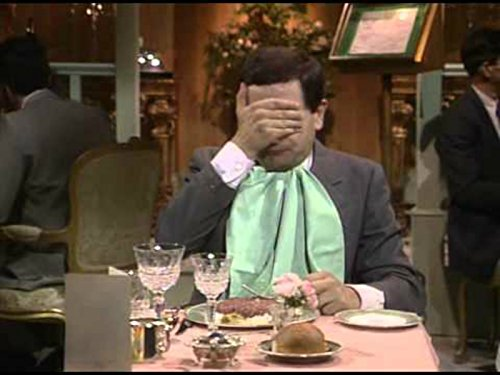

In [148]:
pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

**1. Провести Exploratory Data Analysis і висунути гіпотези щодо впливу окремих ознак на цільову ознаку y.**

In [149]:
raw_df['target'] = (raw_df['y'] == 'yes').astype(int)
BASE_RATE = raw_df['target'].mean()
print(BASE_RATE)

0.11265417111780131


In [150]:
data = raw_df
anomaly = data[(data['pdays'] == 999) & (data['previous'] > 0)]
print(len(anomaly))

4110


In [151]:
print(raw_df.shape)
raw_df.info(show_counts=True)
# raw_df.head()
print('пропусків:', raw_df.isna().sum().sum())
print('дублікатів:', raw_df.duplicated().sum())

(41188, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   411

In [152]:
raw_df.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,target
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,380,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
9,25,services,single,high.school,no,yes,no,telephone,may,mon,50,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0


In [153]:
raw_df[raw_df.duplicated(keep=False)]   # дивлюсь дублікати

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,target
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no,0
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no,0
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no,0
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no,0
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,43,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no,0
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no,0


In [154]:
# дублікати без зайвих колонок
dups = raw_df[raw_df.duplicated(keep=False)].sort_values(list(raw_df.columns))
print(dups.shape)
dups[['age', 'job', 'marital', 'education', 'duration', 'campaign',
      'pdays', 'previous', 'month', 'day_of_week', 'euribor3m', 'y']]

(24, 22)


,age,job,marital,education,duration,campaign,pdays,previous,month,day_of_week,euribor3m,y
28476,24,services,single,high.school,114,1,999,0,apr,tue,1.423,no
28477,24,services,single,high.school,114,1,999,0,apr,tue,1.423,no
14155,27,technician,single,professional.course,331,2,999,0,jul,mon,4.962,no
14234,27,technician,single,professional.course,331,2,999,0,jul,mon,4.962,no
18464,32,technician,single,professional.course,128,1,999,0,jul,thu,4.968,no
18465,32,technician,single,professional.course,128,1,999,0,jul,thu,4.968,no
32505,35,admin.,married,university.degree,348,4,999,0,may,fri,1.313,no
32516,35,admin.,married,university.degree,348,4,999,0,may,fri,1.313,no
12260,36,retired,married,unknown,88,1,999,0,jul,thu,4.966,no
12261,36,retired,married,unknown,88,1,999,0,jul,thu,4.966,no


Усі дублікати залишено. Id клієнта в наборі немає, тому природу збігів встановити неможливо.

Обидва варіанти зачіпають 0.03 % рядків, тож рішення на результат не впливає; обрано варіант, що не втрачає даних. Точний збіг по полю duration у кожній парі свідчить радше на користь технічного дублювання. Вплив дедуплікації на метрику планується виміряти після побудови пайплайна: розбиття фіксується, drop_duplicates() застосовується лише до train, обидва варіанти оцінюються на тій самій валідації по кількох random_state.

In [155]:
raw_df['y'].value_counts()
raw_df['y'].value_counts(normalize=True)

,proportion
y,
no,0.887346
yes,0.112654


In [156]:
TARGET_PALETTE = {'no': 'steelblue', 'yes': 'seagreen'}

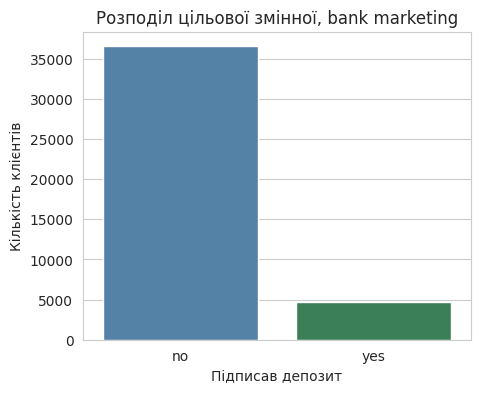

In [157]:
plt.figure(figsize=(5, 4))
sns.countplot(data=raw_df, x='y', hue='y',
              palette=TARGET_PALETTE, legend=False)
plt.title('Розподіл цільової змінної, bank marketing')
plt.ylabel('Кількість клієнтів')
plt.xlabel('Підписав депозит')
plt.show()

In [158]:
print('accuracy моделі "завжди no":', (raw_df['y'] == 'no').mean())

accuracy моделі "завжди no": 0.8873458288821987


Якщо просто обрати модель «завжди no» то маємо accuracy 0.8873 на цьому наборі, не знаходячи жодного вкладника. Метрика, яку можна виграти, нічого не передбачивши, для цієї задачі непридатна.

In [159]:
raw_df['age_bin']      = pd.cut(raw_df['age'], bins=[-np.inf, 25, 30, 40, 50, 60, 70, np.inf],
                                labels=['<=25', '26-30', '31-40', '41-50', '51-60', '61-70', '71+'])
raw_df['campaign_bin'] = pd.cut(raw_df['campaign'], bins=[-np.inf, 1, 2, 5, np.inf],
                                labels=['1', '2', '3-5', '6+'])
raw_df['previous_bin'] = pd.cut(raw_df['previous'], bins=[-np.inf, 0, 1, 2, np.inf],
                                labels=['0', '1', '2', '3+'])

age_rate = (raw_df.groupby('age_bin', observed=True)
                  .agg(n=('target', 'size'), rate=('target', 'mean')))
age_rate

,n,rate
age_bin,,
<=25,1666,0.209484
26-30,5717,0.135561
31-40,16385,0.097467
41-50,10240,0.081738
51-60,6270,0.106539
61-70,488,0.434426
71+,422,0.478673


In [160]:
# check if all values covered
print(raw_df[['age_bin', 'campaign_bin', 'previous_bin']].isna().sum())

age_bin         0
campaign_bin    0
previous_bin    0
dtype: int64


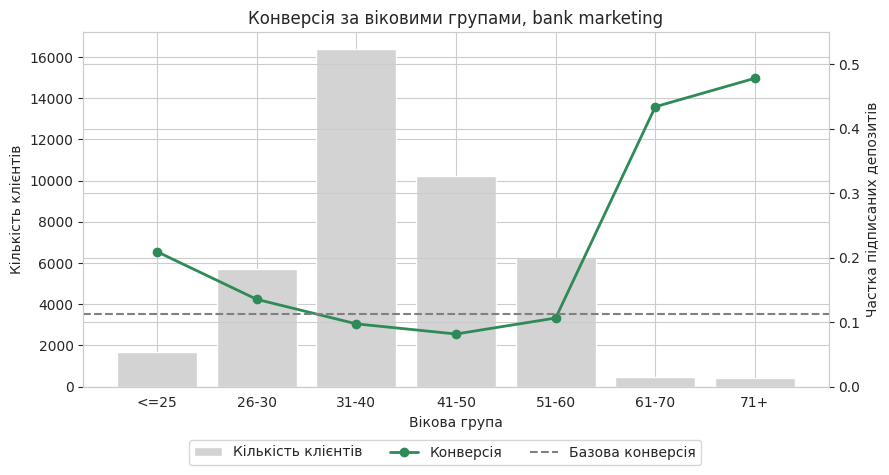

In [161]:
fig, ax1 = plt.subplots(figsize=(9, 4.5))

ax1.bar(age_rate.index.astype(str), age_rate['n'],
        color='lightgrey', label='Кількість клієнтів')
ax1.set_ylabel('Кількість клієнтів')
ax1.set_xlabel('Вікова група')

ax2 = ax1.twinx()
ax2.plot(age_rate.index.astype(str), age_rate['rate'],
         color='seagreen', marker='o', linewidth=2, label='Конверсія')
ax2.axhline(BASE_RATE, color='grey', linestyle='--', label='Базова конверсія')
ax2.set_ylabel('Частка підписаних депозитів')
ax2.set_ylim(0, 0.55)

fig.legend(loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06))
ax1.set_title('Конверсія за віковими групами, bank marketing')
plt.tight_layout()
plt.show()

In [162]:
age_rate['yes'] = (age_rate['n'] * age_rate['rate']).round().astype(int)
age_rate

,n,rate,yes
age_bin,,,
<=25,1666,0.209484,349
26-30,5717,0.135561,775
31-40,16385,0.097467,1597
41-50,10240,0.081738,837
51-60,6270,0.106539,668
61-70,488,0.434426,212
71+,422,0.478673,202


Конверсія за віком немонотонна: вона має мінімум у групі 41 до 50 років (8.2% при 10240 клієнтах) і підвищується на обох краях діапазону, до 20.9% у групі до 25 років включно і до 43.4 та 47.9% у групах 61 до 70 і старших за 70. Останні дві групи малі, 488 і 422 клієнти, але містять 212 і 202 позитивів, тому підвищення виміряне, а не шумове.
Для лінійної моделі це означає, що самого віку як числової ознаки недостатньо, і потрібне або розбиття на групи, або бінарна ознака для крайніх діапазонів; дерево і бустинг вловлять цю форму без допомоги.

In [163]:
pd.crosstab(raw_df['age_bin'], raw_df['job'] == 'retired', normalize='index').round(3)

job,False,True
age_bin,,
<=25,0.999,0.001
26-30,0.999,0.001
31-40,0.998,0.002
41-50,0.992,0.008
51-60,0.853,0.147
61-70,0.393,0.607
71+,0.095,0.905


In [164]:
pd.crosstab(raw_df['age_bin'], raw_df['job'] == 'retired',
            values=raw_df['target'], aggfunc='mean',
            normalize=False).round(3)

job,False,True
age_bin,,
<=25,0.210,0.000
26-30,0.136,0.000
31-40,0.098,0.062
41-50,0.082,0.071
51-60,0.104,0.123
61-70,0.406,0.453
71+,0.575,0.469


In [165]:
pd.crosstab(raw_df['age_bin'], raw_df['job'] == 'retired')

job,False,True
age_bin,,
<=25,1665,1
26-30,5713,4
31-40,16353,32
41-50,10155,85
51-60,5350,920
61-70,192,296
71+,40,382


Підвищення на старшому краю значною мірою пояснюється часткою пенсіонерів. Вік і зайнятість несуть частково однакову інформацію, тому при читанні важливості ознак очікую, що вони поділять її між собою, і жодна не виглядатиме настільки сильною, як показує окремий аналіз.

**2. Описати, які методи ви вважаєте доречним використовувати і обрати метрику оцінки якості моделей (метрику треба обґрунтувати).**

Задача є бінарною класифікацією на табличних даних: 41 188 рядків, 20 ознак, з них 10 категоріальних і 10 числових, пропусків немає. Цільовий клас займає 11.27 % (4 640 спостережень із 41 188), тобто вибірка помітно незбалансована.

Щодо методів. Дані змішаного типу, зв'язки між ознаками і таргетом здебільшого нелінійні (конверсія за віком не монотонна, а має підвищення на обох краях діапазону), а частина ознак закодована службовими значеннями, як pdays=999.

Логістична регресія береться як інтерпретовна база: вона дає коефіцієнти, які можна показати замовнику, але потребує кодування категорій, масштабування числових ознак і окремої обробки pdays, бо для лінійної моделі 999 поруч зі значеннями від 0 до 27 не є службовою міткою, а є величезним числом.
kNN додається як метод, що не робить жодних припущень про форму залежності, проте на цих даних він у невигідному становищі: після one-hot кодування простір стає високорозмірним, модель чутлива до масштабу і до викидів у campaign та age, а ймовірності на виході приймають лише k+1 різних значень, що само по собі обмежує якість ранжування.
Дерево рішень працює з категоріями і нелінійностями природно, ігнорує викиди й монотонні перетворення, і дає зрозумілу схему рішень, але одиночне дерево видає стільки різних ймовірностей, скільки має листків.
Градієнтний бустинг очікувано буде найсильнішим, бо усуває саме це обмеження: ансамбль дерев видає неперервну шкалу ймовірностей і вловлює взаємодії ознак, яких одиночне дерево не бачить.

Ознака duration з моделювання виключена. Її кореляція з таргетом дорівнює 0.405, медіана тривалості дзвінка становить 163.5 секунди при відмові проти 449 секунд при згоді, тобто це найсильніший предиктор у наборі. Але її значення стає відомим лише після завершення дзвінка, коли відповідь клієнта вже відома, тому в момент, коли модель має видати прогноз, цієї величини не існує. Я використовую її лише для довідки, як недосяжну верхню межу якості, і не включаю в жодну модель, що претендує на застосування.

Щодо метрики. Accuracy для цієї задачі непридатна. Тривіальна модель, яка завжди відповідає no, дає accuracy 0.8873, не знайшовши жодного вкладника, тобто метрику можна виграти, нічого не передбачивши. На прикладі валідаційної вибірки з 8 000 спостережень і 900 позитивів модель, яка відбирає 1 000 клієнтів і вгадує серед них 450, отримує accuracy 0.875 і програє тривіальній моделі, маючи при цьому recall 0.5 і precision 0.45. Коли метрика і здоровий глузд розходяться, помилка в метриці.

Постановку задачі я формулюю через обмеження кол-центру, і це змінює те, що саме модель має робити. Розрахунок за цінами 5 євро за дзвінок і 200 євро маржі з депозиту показує, що обдзвін усієї бази дає 140 000 євро проти 85 000 у відібраної тисячі, тобто без обмеження ресурсу модель узагалі не потрібна: одна вдала спроба окуповує сорок невдалих, а базова конверсія дає одну вдалу на дев'ять. Але кол-центр має скінченну ємність, і за фіксованого бюджету в 1 000 дзвінків випадковий вибір дає близько 113 депозитів, а відбір моделлю 450, тобто вчетверо більше за той самий бюджет і приріст у 67 400 євро. Отже задача моделі не в тому, щоб поставити мітку кожному клієнту, а в тому, щоб упорядкувати базу так, аби вкладники опинилися вгорі списку.

Це задача ранжування, і головна метрика має бути незалежною від порога. Метрика, порахована на одному фіксованому порозі, порівнює не моделі, а пари «модель плюс поріг»: дві моделі з однаковим результатом на тисячі відібраних можуть дати 450 і 225 депозитів на п'ятистах, якщо порядок усередині списку в них різний, а поріг задає кол-центр і може змінитися.

**Тому головною метрикою я обираю PR AUC (average precision)**: обидві її осі стосуються позитивного класу, тому вона реагує на кожне хибне спрацювання, за яке платить кол-центр, і не залежить від того, де проведено межу. При частці позитивів 11.27 % ROC AUC схильна виглядати оптимістично, бо її знаменник містить 36 548 негативів і зайві дзвінки майже не рухають FPR, тоді як precision реагує на кожен. Додаткова перевага PR AUC у тому, що її база дорівнює частці позитивів, 0.1127, тож значення читається безпосередньо як кратність до випадкового відбору. Поряд у таблиці порівняння я наводжу ROC AUC, оскільки він стійкіший до шуму розбиття і залишається загальноприйнятою величиною для зіставлення з чужими результатами. Третьою колонкою йде lift@1000, безрозмірна величина, яка прямо відповідає на питання замовника, у скільки разів відібраний топ кращий за випадковий вибір, і не залежить від цін.

Поріг класифікації обирається окремо, після вибору моделі, виходячи з реальної ємності кампанії, і до порівняння моделей не входить.

медіана: 2.0
count    41188.000000
mean         2.567593
std          2.770014
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
95%          7.000000
99%         14.000000
max         56.000000
Name: campaign, dtype: float64


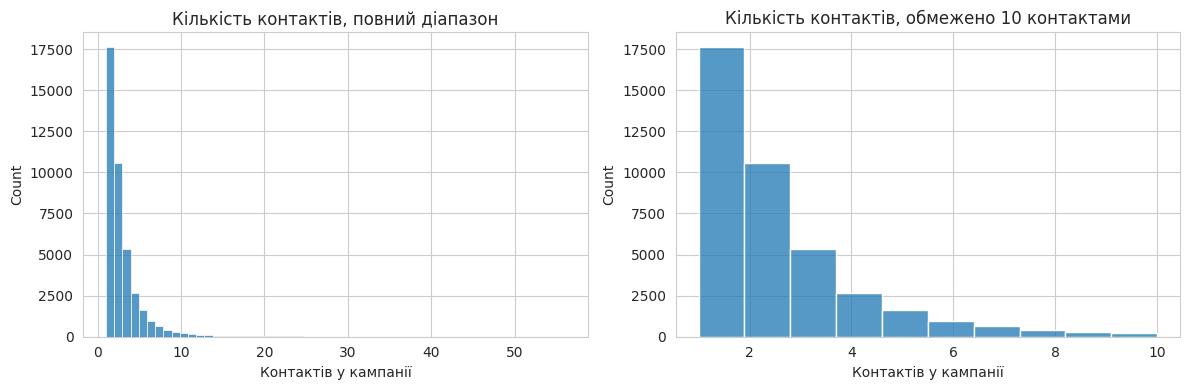

In [166]:
print('медіана:', raw_df['campaign'].median())

# print(raw_df['campaign'].describe())
print(raw_df['campaign'].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw_df['campaign'], bins=56, ax=axes[0])
axes[0].set_title('Кількість контактів, повний діапазон')
axes[0].set_xlabel('Контактів у кампанії')

sns.histplot(raw_df.loc[raw_df['campaign'] <= 10, 'campaign'],
             bins=10, ax=axes[1])
axes[1].set_title('Кількість контактів, обмежено 10 контактами')
axes[1].set_xlabel('Контактів у кампанії')
plt.tight_layout()


In [167]:
camp_rate = (raw_df.groupby('campaign')
                   .agg(n=('target', 'size'), rate=('target', 'mean')))
camp_rate['yes'] = (camp_rate['n'] * camp_rate['rate']).round().astype(int)
camp_rate.head(12).round(4)

,n,rate,yes
campaign,,,
1,17642,0.1304,2300
2,10570,0.1146,1211
3,5341,0.1075,574
4,2651,0.0939,249
5,1599,0.0750,120
6,979,0.0766,75
7,629,0.0604,38
8,400,0.0425,17
9,283,0.0601,17


In [168]:
tail = raw_df[raw_df['campaign'] >= 6]
print(len(tail), round(tail['target'].mean(), 4), tail['target'].sum())

3385 0.0549 186


рахую чи поділ на один і більше не скриє дані

In [169]:
n_all  = len(raw_df)
yes_all = raw_df['target'].sum()

n_1   = (raw_df['campaign'] == 1).sum()
yes_1 = raw_df.loc[raw_df['campaign'] == 1, 'target'].sum()

n_2plus   = n_all - n_1
yes_2plus = yes_all - yes_1

print(n_2plus, yes_2plus, yes_2plus / n_2plus)

23546 2340 0.09937993714431326


In [170]:
raw_df['campaign_bin'] = pd.cut(raw_df['campaign'],
                                bins=[-np.inf, 1, 2, 5, np.inf],
                                labels=['1', '2','3-5', '6+'])

camp_bin = (raw_df.groupby('campaign_bin', observed=True)
                  .agg(n=('target', 'size'), rate=('target', 'mean')))
camp_bin['yes'] = (camp_bin['n'] * camp_bin['rate']).round().astype(int)
camp_bin.round(4)

,n,rate,yes
campaign_bin,,,
1,17642,0.1304,2300
2,10570,0.1146,1211
3-5,9591,0.0983,943
6+,3385,0.0549,186


Скільки колонок насправді буде?

In [171]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']

print(raw_df[cat_cols].nunique())
print('разом рівнів:', raw_df[cat_cols].nunique().sum())

job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
dtype: int64
разом рівнів: 53


In [172]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome', 'campaign_bin']

eda_encoded = pd.get_dummies(raw_df[cat_cols], drop_first=False)

print('форма після кодування:', eda_encoded.shape)
print()
rare = eda_encoded.sum().sort_values()
print('десять найрідших колонок:')
print(rare.head(10))
print()
print('колонок з менш ніж 50 одиницями:', (rare < 50).sum())

форма після кодування: (41188, 57)

десять найрідших колонок:
default_yes               3
education_illiterate     18
marital_unknown          80
month_dec               182
job_unknown             330
month_mar               546
month_sep               570
month_oct               718
job_student             875
housing_unknown         990
dtype: int64

колонок з менш ніж 50 одиницями: 2


In [173]:
for col, val in [('default', 'yes'), ('education', 'illiterate')]:
    sub = raw_df[raw_df[col] == val]
    print(f'{col}={val}: {len(sub)} рядків, позитивів {sub["target"].sum()}')

default=yes: 3 рядків, позитивів 0
education=illiterate: 18 рядків, позитивів 4


In [174]:
for k in [20, 50, 100, 200, 500, 1000]:
    print(f'< {k:5d}: {(rare < k).sum()} колонок')

<    20: 2 колонок
<    50: 2 колонок
<   100: 3 колонок
<   200: 4 колонок
<   500: 5 колонок
<  1000: 11 колонок


**Кількість контактів з цим клієнтом до поточної кампанії (previous).**

In [175]:
# Конверсія по кожному значенню:
prev = (raw_df.groupby('previous')
              .agg(n=('target', 'size'), rate=('target', 'mean')))

prev['yes'] = (prev['n'] * prev['rate']).round().astype(int)
prev.round(4)

,n,rate,yes
previous,,,
0,35563,0.0883,3141
1,4561,0.2120,967
2,754,0.4642,350
3,216,0.5926,128
4,70,0.5429,38
5,18,0.7222,13
6,5,0.6000,3
7,1,0.0000,0


In [176]:
# скільки людей лишається вище межі
print((raw_df['previous'] >= 4).sum())
print((raw_df['previous'] >= 2).sum())
print((raw_df['previous'] >= 1).sum())

94
1064
5625


In [177]:
pd.crosstab(raw_df['previous'] > 0, raw_df['poutcome'])

poutcome,failure,nonexistent,success
previous,,,
False,0,35563,0
True,4252,0,1373


In [178]:
sub = raw_df[raw_df['previous'] > 0]

pd.crosstab(sub['previous'], sub['poutcome'],
            values=sub['target'], aggfunc='mean').round(3)

poutcome,failure,success
previous,,
1,0.122,0.597
2,0.258,0.744
3,0.364,0.750
4,0.300,0.725
5,0.333,0.800
6,0.000,0.750
7,NaN,0.000


In [179]:
pd.crosstab(sub['previous'], sub['poutcome'])

poutcome,failure,success
previous,,
1,3696,865
2,434,320
3,88,128
4,30,40
5,3,15
6,1,4
7,0,1


Усередині **failure** конверсія зростає з 0.122 до 0.258 і далі до 0.364. Перші два рядки стоять на 3696 і 434 клієнтах, тобто виміряні надійно. Це втричі від одного контакту до трьох, при тому що результат попередньої кампанії в усіх однаковий і однаково поганий.

Отже **previous** несе власний сигнал понад poutcome. Наполегливість окупається навіть після невдачі, і обидві колонки потрібні моделі.

У колонці **success** картина інша: 0.597, потім плато навколо 0.73 до 0.75. Один стрибок і рівно. Тобто ефект кількості контактів у цій групі є, але майже вичерпується після другого.

In [180]:
raw_df['previous_bin'] = pd.cut(raw_df['previous'],
                                bins=[-np.inf, 0, 1, 2, np.inf],
                                labels=['0', '1', '2', '3+'])

prev_bin = (raw_df.groupby('previous_bin', observed=True)
                  .agg(n=('target', 'size'), rate=('target', 'mean')))
prev_bin['yes'] = (prev_bin['n'] * prev_bin['rate']).round().astype(int)
prev_bin.round(4)

,n,rate,yes
previous_bin,,,
0,35563,0.0883,3141
1,4561,0.2120,967
2,754,0.4642,350
3+,310,0.5871,182


Зони 3 і 4+ злито. Вони давали 0.5926 і 0.5745 на 216 і 94 рядках, тобто різниця лежить у межах похибки й до того ж іде проти напрямку, порушуючи монотонність. Чотири зони дають монотонний спад lift від 5.2 до 0.78, кожна виміряна.

In [181]:
# Універсальна функція, яка рахує lift для будь-якого зрізу.

def slice_lift(df, mask, label, base_rate=BASE_RATE):
    """Конверсія і lift для довільної підгрупи, з розміром бази поруч."""
    sub = df[mask]
    n = len(sub)
    yes = int(sub['target'].sum())
    rate = yes / n if n else np.nan
    return {
        'ознака': label,
        'n': n,
        'частка бази': n / len(df),
        'конверсія': rate,
        'lift': rate / base_rate,
        'позитивів': yes,
    }

In [182]:

slices = [
    (raw_df['pdays'] < 999,                    'pdays < 999'),
    (raw_df['poutcome'] == 'success',          'poutcome = success'),
    (raw_df['previous'] >= 3,                  'previous >= 3'),
    (raw_df['age'] > 70,                       'age > 70'),
    (raw_df['job'] == 'retired',               'job = retired'),
    (raw_df['campaign'] >= 6,                  'campaign >= 6'),
    (raw_df['month'].isin(['mar', 'sep', 'oct', 'dec']), 'month у mar/sep/oct/dec'),
    (raw_df['contact'] == 'cellular',          'contact = cellular'),
]

lift_table = pd.DataFrame([slice_lift(raw_df, m, lbl) for m, lbl in slices])
lift_table = lift_table.sort_values('lift', ascending=False)

lift_table.style.format({
    'частка бази': '{:.1%}',
    'конверсія': '{:.4f}',
    'lift': '{:.2f}',
})

,ознака,n,частка бази,конверсія,lift,позитивів
1,poutcome = success,1373,3.3%,0.6511,5.78,894
0,pdays < 999,1515,3.7%,0.6383,5.67,967
2,previous >= 3,310,0.8%,0.5871,5.21,182
3,age > 70,422,1.0%,0.4787,4.25,202
6,month у mar/sep/oct/dec,2016,4.9%,0.4643,4.12,936
4,job = retired,1720,4.2%,0.2523,2.24,434
7,contact = cellular,26144,63.5%,0.1474,1.31,3853
5,campaign >= 6,3385,8.2%,0.0549,0.49,186


In [183]:
# допоміжна таблиця, подивитись вплив
lift_table['вплив'] = (lift_table['позитивів']
                       * (lift_table['lift'] - 1).abs()).round().astype(int)

lift_table = lift_table.sort_values('вплив', ascending=False)

lift_table.style.format({
    'частка бази': '{:.1%}',
    'конверсія': '{:.4f}',
    'lift': '{:.2f}',
})

,ознака,n,частка бази,конверсія,lift,позитивів,вплив
0,pdays < 999,1515,3.7%,0.6383,5.67,967,4512
1,poutcome = success,1373,3.3%,0.6511,5.78,894,4273
6,month у mar/sep/oct/dec,2016,4.9%,0.4643,4.12,936,2922
7,contact = cellular,26144,63.5%,0.1474,1.31,3853,1188
2,previous >= 3,310,0.8%,0.5871,5.21,182,766
3,age > 70,422,1.0%,0.4787,4.25,202,656
4,job = retired,1720,4.2%,0.2523,2.24,434,538
5,campaign >= 6,3385,8.2%,0.0549,0.49,186,95


In [184]:
print('Сила зрізу проти охоплення. Колонка "вплив" = позитивів × |lift − 1|,')
print('орієнтовна величина для порівняння зрізів між собою, не метрика важливості.')

Сила зрізу проти охоплення. Колонка "вплив" = позитивів × |lift − 1|,
орієнтовна величина для порівняння зрізів між собою, не метрика важливості.


**pdays**

count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays, dtype: float64


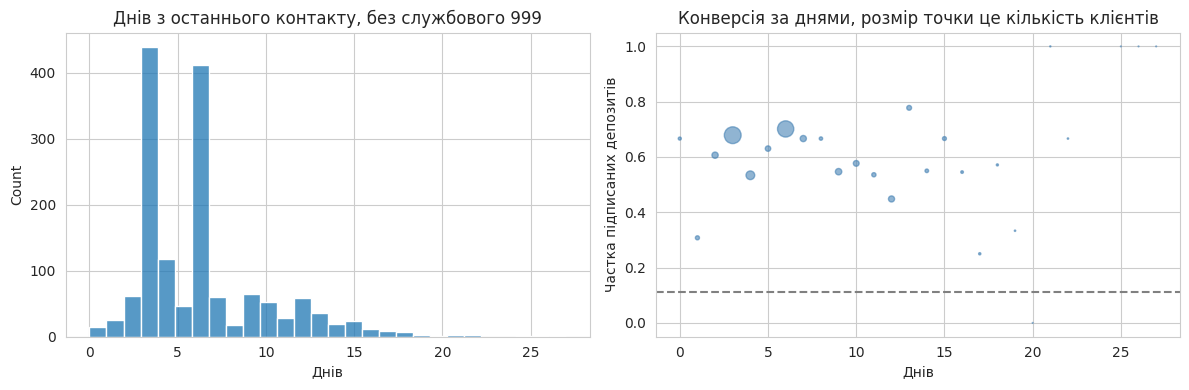

In [185]:
# Дивлюсь на розподіл реальних значень, без службового 999
real = raw_df[raw_df['pdays'] < 999]

print(real['pdays'].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(real['pdays'], bins=28, ax=axes[0])
axes[0].set_title('Днів з останнього контакту, без службового 999')
axes[0].set_xlabel('Днів')

pdays_rate = (real.groupby('pdays')
                  .agg(n=('target', 'size'), rate=('target', 'mean')))
axes[1].scatter(pdays_rate.index, pdays_rate['rate'],
                s=pdays_rate['n'] / 3, alpha=0.6, color='steelblue')
axes[1].axhline(BASE_RATE, color='grey', linestyle='--')
axes[1].set_title('Конверсія за днями, розмір точки це кількість клієнтів')
axes[1].set_xlabel('Днів')
axes[1].set_ylabel('Частка підписаних депозитів')
plt.tight_layout()

Лівий графік: два піки.
Гістограма двогорба: 400+ клієнтів на третьому дні і 400+ на шостому, а між ними провал до 100+. Це не властивість клієнтів, це розклад роботи кол-центру: повторний дзвінок роблять через три або через шість днів, тобто через дні чи через тиждень.

In [186]:
pd.crosstab(raw_df['pdays'] == 999, raw_df['previous'] == 0)

previous,False,True
pdays,,
False,1515,0
True,4110,35563


Перевірено, що **pdays_known** разом із **previous_bin** розрізняють усі три групи: клієнтів із записаною датою і previous = 0 у даних немає (кростаб дає нульову клітинку), тому відмова від числа днів не призводить до втрати поділу.

In [187]:
raw_df['pdays_known'] = (raw_df['pdays'] < 999).astype(int)

**ready to dive**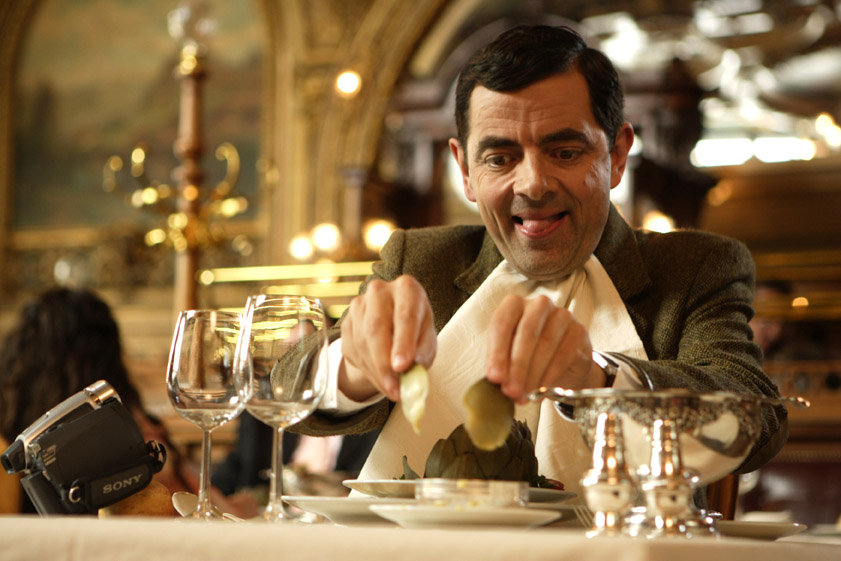

In [188]:
def conversion_table(df, col, base_rate=BASE_RATE):
    t = (df.groupby(col, observed=True)
           .agg(n=('target', 'size'), yes=('target', 'sum')))
    t['rate'] = t['yes'] / t['n']
    t['lift'] = t['rate'] / base_rate
    return t.sort_values('rate', ascending=False)

In [189]:
conversion_table(raw_df, 'job').round(4)

,n,yes,rate,lift
job,,,,
student,875,275,0.3143,2.7898
retired,1720,434,0.2523,2.2398
unemployed,1014,144,0.1420,1.2606
admin.,10422,1352,0.1297,1.1515
management,2924,328,0.1122,0.9957
unknown,330,37,0.1121,0.9953
technician,6743,730,0.1083,0.9610
self-employed,1421,149,0.1049,0.9308
housemaid,1060,106,0.1000,0.8877


In [190]:
raw_df.groupby('job', observed=True)['age'].describe()[['count', '25%', '50%', '75%']].round(1)

,count,25%,50%,75%
job,,,,
admin.,10422.0,31.0,36.0,44.0
blue-collar,9254.0,33.0,39.0,46.0
entrepreneur,1456.0,35.0,41.0,49.0
housemaid,1060.0,37.0,45.0,53.0
management,2924.0,35.0,42.0,50.0
retired,1720.0,56.0,59.0,69.0
self-employed,1421.0,32.0,39.0,47.0
services,3969.0,31.0,36.0,45.0
student,875.0,22.0,25.0,29.0


In [191]:
print(raw_df.groupby(raw_df['job'] == 'unknown')['previous'].mean().round(3))
print()
for col in ['education', 'marital', 'default', 'housing', 'loan']:
    unk = raw_df.loc[raw_df['job'] == 'unknown', col].eq('unknown').mean()
    all_ = raw_df[col].eq('unknown').mean()
    print(f'{col:10s} unknown серед job=unknown: {unk:.3f}, по базі: {all_:.3f}')

job
False    0.173
True     0.155
Name: previous, dtype: float64

education  unknown серед job=unknown: 0.397, по базі: 0.042
marital    unknown серед job=unknown: 0.027, по базі: 0.002
default    unknown серед job=unknown: 0.461, по базі: 0.209
housing    unknown серед job=unknown: 0.015, по базі: 0.024
loan       unknown серед job=unknown: 0.015, по базі: 0.024


housing і loan йдуть проти тренду: 0.015 проти базових 0.024, тобто серед цих людей невідомої іпотеки менше, ніж у середньому.

In [192]:
print((raw_df['housing'] == 'unknown').eq(raw_df['loan'] == 'unknown').all())

True


Пропуски  **unknown** не є незалежними. Серед клієнтів з **невідомою професією** невідома освіта трапляється в 39.7 % випадків при базовій частоті 4.2 %, невідомий сімейний стан у 2.7 % при базових 0.2 %. Кількість попередніх контактів у цій групі не відрізняється від середньої (0.155 проти 0.173), тому версія про нових клієнтів не підтверджується. Це радше ознака погано заповненої анкети, ніж характеристика людини.

In [193]:
unknown_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan']
raw_df['n_unknown'] = (raw_df[unknown_cols] == 'unknown').sum(axis=1)

(raw_df.groupby('n_unknown')
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .assign(lift=lambda t: t['rate'] / BASE_RATE)
       .round(4))

,n,rate,lift
n_unknown,,,
0,30488,0.1266,1.1236
1,9034,0.0695,0.6171
2,1338,0.0972,0.8625
3,306,0.0752,0.6672
4,20,0.0000,0.0000
5,2,0.0000,0.0000


In [194]:
# анкета заповнена повністю чи ні?
raw_df['has_unknown'] = (raw_df['n_unknown'] > 0).astype(int)

(raw_df.groupby('has_unknown')
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .assign(lift=lambda t: t['rate'] / BASE_RATE)
       .round(4))

,n,rate,lift
has_unknown,,,
0,30488,0.1266,1.1236
1,10700,0.0730,0.6479


In [195]:
pd.crosstab(raw_df['has_unknown'], raw_df['contact'], normalize='index').round(3)

contact,cellular,telephone
has_unknown,,
0,0.671,0.329
1,0.533,0.467


In [196]:
pd.crosstab(raw_df['month'], raw_df['has_unknown'], normalize='index').round(3)

has_unknown,0,1
month,,
apr,0.804,0.196
aug,0.756,0.244
dec,0.863,0.137
jul,0.708,0.292
jun,0.680,0.320
mar,0.883,0.117
may,0.707,0.293
nov,0.852,0.148
oct,0.894,0.106


In [197]:
(raw_df.groupby(['month', 'has_unknown'], observed=True)
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .round(4))

n    rate
month has_unknown              
apr   0            2115  0.2213
      1             517  0.1373
aug   0            4673  0.1141
      1            1505  0.0811
dec   0             157  0.4713
      1              25  0.6000
jul   0            5081  0.1008
      1            2093  0.0655
jun   0            3614  0.1251
      1            1704  0.0628
mar   0             482  0.5104
      1              64  0.4688
may   0            9733  0.0719
      1            4036  0.0461
nov   0            3496  0.1044
      1             605  0.0843
oct   0             642  0.4470
      1              76  0.3684
sep   0             495  0.4485
      1              75  0.4533

Виникає підозра, що ознака **has_unknown** позначає період, а не якість запису: частка рядків з незаповненими полями коливається від 10.6 % у жовтні до 32.0 % у червні, і місяці з високою часткою пропусків збігаються з місяцями низької конверсії. Перевіряю нижче, чи зберігається ефект при фіксованому місяці та каналі.

In [198]:
# скільки з різниці в конверсії пояснюється каналом:
(raw_df.groupby(['contact', 'has_unknown'])
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .assign(lift=lambda t: t['rate'] / BASE_RATE)
       .round(4))

n    rate    lift
contact   has_unknown                       
cellular  0            20443  0.1601  1.4212
          1             5701  0.1017  0.9031
telephone 0            10045  0.0583  0.5178
          1             4999  0.0402  0.3569

Ефект **has_unknown** зберігається при фіксованому каналі зв'язку: серед мобільних контактів конверсія падає з 0.1601 до 0.1017, серед стаціонарних з 0.0583 до 0.0402, тобто в 1.57 і 1.45 раза відповідно. Канал пояснює частину загальної різниці, але не всю.

In [199]:
(raw_df.groupby(['month', 'has_unknown'], observed=True)
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .round(4))

n    rate
month has_unknown              
apr   0            2115  0.2213
      1             517  0.1373
aug   0            4673  0.1141
      1            1505  0.0811
dec   0             157  0.4713
      1              25  0.6000
jul   0            5081  0.1008
      1            2093  0.0655
jun   0            3614  0.1251
      1            1704  0.0628
mar   0             482  0.5104
      1              64  0.4688
may   0            9733  0.0719
      1            4036  0.0461
nov   0            3496  0.1044
      1             605  0.0843
oct   0             642  0.4470
      1              76  0.3684
sep   0             495  0.4485
      1              75  0.4533

Створена ознака has_unknown позначає рядки, де хоча б одне з шести полів анкети не заповнене (26.0% бази). Конверсія в цій групі 0.0730 проти 0.1266, lift 0.65 проти 1.12. Ефект не зводиться ні до каналу зв'язку, ні до періоду: при фіксованому каналі різниця становить 1.57 раза для мобільних і 1.45 для стаціонарних, при фіксованому місяці 1.4 до 2.0 разів у чотирьох найбільших місяцях. Пропуски не є незалежними: серед клієнтів з невідомою професією невідома освіта трапляється в 39.7 % випадків при базовій частоті 4.2 %. Причина зв'язку з наявних даних не встановлюється, тому ознака тлумачиться як маркер умов збору даних, а не як характеристика клієнта.

# **education**

In [200]:
conversion_table(raw_df, 'education').round(4)

,n,yes,rate,lift
education,,,,
illiterate,18,4,0.2222,1.9726
unknown,1731,251,0.1450,1.2872
university.degree,12168,1670,0.1372,1.2183
professional.course,5243,595,0.1135,1.0074
high.school,9515,1031,0.1084,0.9618
basic.4y,4176,428,0.1025,0.9098
basic.6y,2292,188,0.0820,0.7281
basic.9y,6045,473,0.0782,0.6946


In [201]:
raw_df[raw_df['education'] == 'unknown']['age'].describe().round(1)
print(raw_df.groupby(raw_df['education'] == 'unknown')['age'].median())

education
False    38.0
True     43.0
Name: age, dtype: float64


In [202]:
# перевіряю частку похилого віку
unk = raw_df['education'] == 'unknown'
print(raw_df.groupby(unk)['age'].quantile([0.75, 0.9, 0.95]).round(1))
print()
print('частка старших за 60:')
print(raw_df.groupby(unk).apply(lambda g: (g['age'] > 60).mean(), include_groups=False).round(4))

education      
False      0.75    47.0
           0.90    54.0
           0.95    58.0
True       0.75    52.0
           0.90    58.0
           0.95    63.0
Name: age, dtype: float64

частка старших за 60:
education
False    0.0204
True     0.0607
dtype: float64


In [203]:
(raw_df.groupby(['age_bin', raw_df['education'].eq('unknown').rename('edu_unknown')],
                observed=True)
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .round(4))

n    rate
age_bin edu_unknown               
<=25    False         1537  0.1932
        True           129  0.4031
26-30   False         5558  0.1355
        True           159  0.1384
31-40   False        15968  0.0974
        True           417  0.1007
41-50   False         9704  0.0811
        True           536  0.0933
51-60   False         5885  0.1081
        True           385  0.0831
61-70   False          427  0.4426
        True            61  0.3770
71+     False          378  0.4550
        True            44  0.6818

Підвищена конверсія рівня **education** = **unknown** (lift 1.29) пояснюється віковим складом групи: серед них 6.07 % старших за 60 років проти 2.04 % по базі. При фіксованій віковій групі різниця зникає (0.0974 проти 0.1007 у віці 30 до 40, 0.1081 проти 0.0831 у віці 50 до 60). Рівень залишається окремим, але власного сигналу не несе.

Рівень **illiterate** (18 рядків, 4 позитиви) об'єднаю з **basic.4y** як найближчим за змістом. Конверсія рівня не вимірюється при такому розмірі, а окрема колонка створює ризик відсутності рівня в частині фолдів крос-валідації.

In [204]:
raw_df['education'] = raw_df['education'].replace('illiterate', 'basic.4y')
print((raw_df['education'] == 'illiterate').sum())   # 0

0


# **marital**

In [205]:
conversion_table(raw_df, 'marital').round(4)

,n,yes,rate,lift
marital,,,,
unknown,80,12,0.1500,1.3315
single,11568,1620,0.1400,1.2431
divorced,4612,476,0.1032,0.9162
married,24928,2532,0.1016,0.9016


In [206]:
raw_df['is_single'] = (raw_df['marital'] == 'single').astype(int)

In [207]:
(raw_df.groupby('is_single')
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .assign(lift=lambda t: t['rate'] / BASE_RATE)
       .round(4))

,n,rate,lift
is_single,,,
0,29620,0.102,0.9051
1,11568,0.140,1.2431


Найслабша категоріальна ознака з побачених. Розкид lift від 0.90 до 1.24 серед вимірюваних рівнів, тобто вся колонка вкладається в діапазон, менший за один із контрастів у job. Робимо її бінарною ознакою.

# **default, housing, loan**

In [208]:
for col in ['default', 'housing', 'loan']:
    print(conversion_table(raw_df, col).round(4), '\n')

             n   yes    rate    lift
default                             
no       32588  4197  0.1288  1.1432
unknown   8597   443  0.0515  0.4574
yes          3     0  0.0000  0.0000 

             n   yes    rate    lift
housing                             
yes      21576  2507  0.1162  1.0314
no       18622  2026  0.1088  0.9658
unknown    990   107  0.1081  0.9594 

             n   yes    rate    lift
loan                                
no       33950  3850  0.1134  1.0066
yes       6248   683  0.1093  0.9704
unknown    990   107  0.1081  0.9594 



In [209]:
print((raw_df['housing'] == 'unknown').eq(raw_df['loan'] == 'unknown').all())

True


In [210]:
(raw_df.groupby(['age_bin', 'housing'], observed=True)
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .round(4))

n    rate
age_bin housing              
<=25    no        733  0.1896
        unknown    47  0.2340
        yes       886  0.2246
26-30   no       2590  0.1378
        unknown   128  0.1328
        yes      2999  0.1337
31-40   no       7408  0.0972
        unknown   389  0.0720
        yes      8588  0.0989
41-50   no       4669  0.0747
        unknown   255  0.0941
        yes      5316  0.0873
51-60   no       2832  0.1024
        unknown   151  0.1060
        yes      3287  0.1101
61-70   no        208  0.4087
        unknown    11  0.6364
        yes       269  0.4461
71+     no        182  0.4725
        unknown     9  0.4444
        yes       231  0.4848

Ознаки **housing** і **loan** виключені з моделі. Маргінальний розкид lift становить 0.96 до 1.03 в обох, тобто менше 8 % відносної різниці на десятках тисяч рядків. Перевірка на взаємодію з віком не виявила ефекту: всередині чотирьох найбільших вікових груп різниця конверсії між наявністю та відсутністю іпотеки лежить у межах одного відсоткового пункту і не змінює напрямку. Рівень unknown у цих колонках (990 рядків, порядково однакових в обох) уже врахований ознакою has_unknown.

# **contact, poutcome, day_of_week**

In [211]:
for col in ['contact', 'poutcome', 'day_of_week']:
    print(conversion_table(raw_df, col).round(4), '\n')

               n   yes    rate    lift
contact                               
cellular   26144  3853  0.1474  1.3082
telephone  15044   787  0.0523  0.4644 

                 n   yes    rate    lift
poutcome                                
success       1373   894  0.6511  5.7799
failure       4252   605  0.1423  1.2630
nonexistent  35563  3141  0.0883  0.7840 

                n   yes    rate    lift
day_of_week                            
thu          8623  1045  0.1212  1.0757
tue          8090   953  0.1178  1.0457
wed          8134   949  0.1167  1.0357
fri          7827   846  0.1081  0.9595
mon          8514   847  0.0995  0.8831 



In [212]:
pd.crosstab(raw_df['day_of_week'], raw_df['contact'], normalize='index').round(3)

contact,cellular,telephone
day_of_week,,
fri,0.593,0.407
mon,0.650,0.350
thu,0.673,0.327
tue,0.631,0.369
wed,0.621,0.379


**День тижня** дає слабкий, але виміряний ефект: конверсія падає з 0.1212 у четвер до 0.0995 у понеділок, тобто на 22 % відносно. Різниця не пояснюється складом дзвінків: частка мобільних контактів у понеділок (0.650) навіть вища за середню, тоді як мобільний канал загалом конвертує втричі краще за стаціонарний. Корисний контраст у колонці один, понеділок проти решти днів.

Рішення створити бінарну колонку.

In [213]:
raw_df['is_monday'] = (raw_df['day_of_week'] == 'mon').astype(int)

In [214]:
# як розподіляються канали по місяцях:
pd.crosstab(raw_df['month'], raw_df['contact'], normalize='index').round(3)

contact,cellular,telephone
month,,
apr,0.929,0.071
aug,0.956,0.044
dec,0.819,0.181
jul,0.850,0.150
jun,0.154,0.846
mar,0.890,0.110
may,0.401,0.599
nov,0.896,0.104
oct,0.784,0.216


In [215]:
(raw_df.groupby(['month', 'contact'], observed=True)
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .round(4))

n    rate
month contact                
apr   cellular   2445  0.2016
      telephone   187  0.2460
aug   cellular   5909  0.1048
      telephone   269  0.1338
dec   cellular    149  0.5235
      telephone    33  0.3333
jul   cellular   6096  0.0969
      telephone  1078  0.0538
jun   cellular    820  0.4256
      telephone  4498  0.0467
mar   cellular    486  0.5185
      telephone    60  0.4000
may   cellular   5518  0.1113
      telephone  8251  0.0330
nov   cellular   3676  0.0996
      telephone   425  0.1176
oct   cellular    563  0.4494
      telephone   155  0.4000
sep   cellular    482  0.4938
      telephone    88  0.2045

Ознака contact розподілена по місяцях украй нерівномірно: у червні мобільні становлять 15.4 % контактів, у травні 40.1 %, у решті восьми місяців від 78 до 96 %. Травень і червень це перші місяці кампанії за порядком рядків у файлі, отже колонка значною мірою позначає ранній період.
Ефект каналу при фіксованому місяці не сталий: у травні та червні конверсія мобільних перевищує стаціонарні в 3.4 і 9.1 раза, тоді як у квітні, серпні та листопаді стаціонарні конвертують не гірше.

Загалом мобільні клієнти підписують депозит у 1.31 раза частіше за середнє, але це число не можна приймати за чистий ефект каналу. Мобільних було мало саме в травні й червні, на самому початку кампанії, а тоді конверсія була низькою в усіх. Тож частина різниці пояснюється тим, коли людям дзвонили, а не тим, на який телефон. Я залишаю ознаку в моделі як бінарну is_cellular: у колонки лише два значення, тож one-hot дав би дві колонки, де одна повністю повторює іншу. Вплив періоду модель отримає з макроколонок, тому is_cellular покаже вже лише те, що додає сам канал.

In [216]:
raw_df['is_cellular'] = (raw_df['contact'] == 'cellular').astype(int)

In [217]:
print(pd.crosstab(raw_df['poutcome'], raw_df['pdays_known']))
print(pd.crosstab(raw_df['poutcome'], raw_df['pdays_known'],
                  values=raw_df['target'], aggfunc='mean').round(3))

pdays_known      0     1
poutcome                
failure       4110   142
nonexistent  35563     0
success          0  1373
pdays_known      0      1
poutcome                 
failure      0.129  0.514
nonexistent  0.088    NaN
success        NaN  0.651


In [218]:
# Конверсія по рівнях:
conversion_table(raw_df, 'poutcome').round(4)

,n,yes,rate,lift
poutcome,,,,
success,1373,894,0.6511,5.7799
failure,4252,605,0.1423,1.2630
nonexistent,35563,3141,0.0883,0.7840


In [219]:
# Чи дублює previous результат кампанії?
sub = raw_df[raw_df['previous'] > 0]

pd.crosstab(sub['previous'], sub['poutcome'],
            values=sub['target'], aggfunc='mean').round(3)

poutcome,failure,success
previous,,
1,0.122,0.597
2,0.258,0.744
3,0.364,0.750
4,0.300,0.725
5,0.333,0.800
6,0.000,0.750
7,NaN,0.000


In [220]:
# Чи дублює pdays_known результат кампанії?
print(pd.crosstab(raw_df['poutcome'], raw_df['pdays_known']))

pd.crosstab(raw_df['poutcome'], raw_df['pdays_known'],
            values=raw_df['target'], aggfunc='mean').round(3)

pdays_known      0     1
poutcome                
failure       4110   142
nonexistent  35563     0
success          0  1373


pdays_known,0,1
poutcome,,
failure,0.129,0.514
nonexistent,0.088,NaN
success,NaN,0.651


Результат попередньої кампанії є найсильнішою доступною ознакою набору: клієнти з poutcome = success підписують депозит у 5.8 раза частіше за середнього (0.6511 проти 0.1127), а навіть провалена попередня кампанія залишає клієнта кращим за того, з ким ніколи не контактували (0.1423 проти 0.0883).

Три колонки набору, **poutcome, previous і pdays,** описують ту саму підгрупу з 5 625 клієнтів, але не дублюють одна одну: всередині групи failure, де результат попередньої кампанії однаковий, конверсія зростає з 0.122 до 0.364 разом із кількістю контактів (на 3 696 і 88 клієнтах) і становить 0.514 проти 0.129 залежно від того, чи записана дата останнього контакту (на 142 і 4 110 клієнтах).

Тому в модель ідуть усі три у власних формах: poutcome як one-hot, previous_bin як зони 0/1/2/3+, pdays_known як бінарна ознака, тоді як саме число днів не використовується, бо всередині 1515 рядків із реальною датою конверсія від давності практично не залежить (0.65 при 0 до 3 днях проти 0.60 при 6 до 10).

In [221]:
# Перевірка створених колонок, чи не забула.
created = ['age_bin', 'campaign_bin', 'previous_bin', 'pdays_known',
           'has_unknown', 'is_single', 'is_monday', 'n_unknown']

for col in created:
    print(f'{col:15s} {"є" if col in raw_df.columns else "НЕМАЄ"}')

age_bin         є
campaign_bin    є
previous_bin    є
pdays_known     є
has_unknown     є
is_single       є
is_monday       є
n_unknown       є


# **П'ять макроколонок:**
emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed.

In [222]:
# Скільки різних значень?
macro = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
         'euribor3m', 'nr.employed']

print(raw_df[macro].nunique())
print()
print('унікальних комбінацій усіх п\'яти:',
      raw_df[macro].drop_duplicates().shape[0])

emp.var.rate       10
cons.price.idx     26
cons.conf.idx      26
euribor3m         316
nr.employed        11
dtype: int64

унікальних комбінацій усіх п'яти: 375


Euribor це денна ставка, і 316 різних значень на наборі, що охоплює приблизно два з половиною роки, це приблизно кількість робочих днів у цьому періоді.

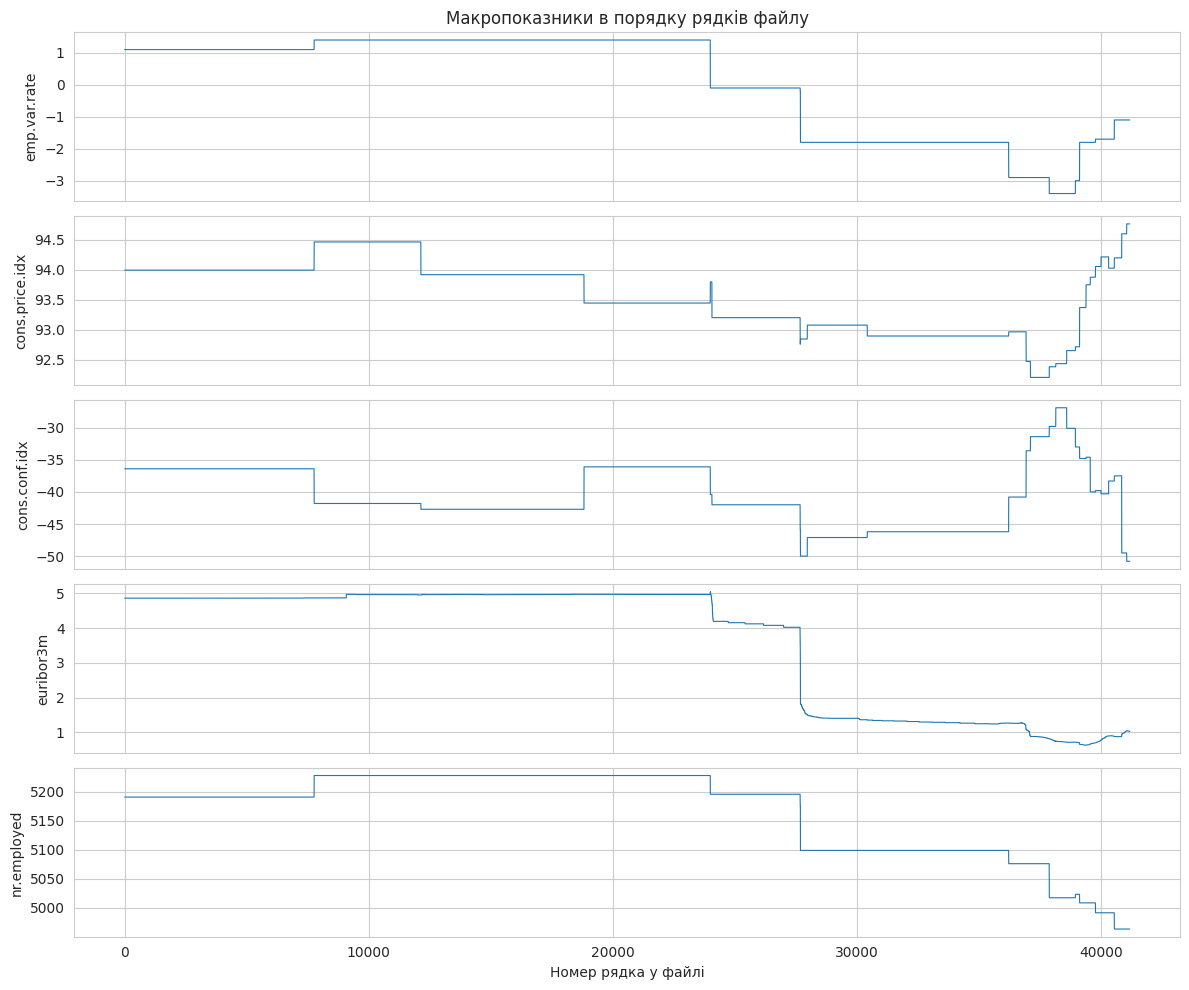

In [223]:
# Чи йдуть вони блоками по порядку рядків?

fig, axes = plt.subplots(5, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, macro):
    ax.plot(raw_df.index, raw_df[col], linewidth=0.8)
    ax.set_ylabel(col)
axes[-1].set_xlabel('Номер рядка у файлі')
axes[0].set_title('Макропоказники в порядку рядків файлу')
plt.tight_layout()

In [224]:
# Кореляції між ними:
raw_df[macro].corr().round(3)

,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.000,0.775,0.196,0.972,0.907
cons.price.idx,0.775,1.000,0.059,0.688,0.522
cons.conf.idx,0.196,0.059,1.000,0.278,0.101
euribor3m,0.972,0.688,0.278,1.000,0.945
nr.employed,0.907,0.522,0.101,0.945,1.000


**euribor3m**

In [225]:
bins = pd.cut(raw_df['euribor3m'], [0, 1, 2, 3, 4, 5.1])
(raw_df.groupby(bins, observed=True)
       .agg(n=('target', 'size'), rate=('target', 'mean'))
       .assign(lift=lambda t: t['rate'] / BASE_RATE)
       .round(4))

,n,rate,lift
euribor3m,,,
"(0.0, 1.0]",3908,0.4570,4.0568
"(1.0, 2.0]",9590,0.1580,1.4023
"(3.0, 4.0]",14,0.0714,0.6341
"(4.0, 5.1]",27676,0.0483,0.4291


In [226]:
raw_df['row'] = np.arange(len(raw_df))

block = (raw_df['month'] != raw_df['month'].shift()).cumsum()

timeline = (raw_df.groupby(block)
            .agg(month=('month', 'first'),
                 n=('row', 'size'),
                 first_row=('row', 'min'),
                 last_row=('row', 'max'),
                 eur_first=('euribor3m', 'first'),
                 eur_last=('euribor3m', 'last'),
                 nr_employed=('nr.employed', 'first'),
                 rate=('target', 'mean')))

print('блоків:', len(timeline))
timeline.round(4)

блоків: 26


,month,n,first_row,last_row,eur_first,eur_last,nr_employed,rate
month,,,,,,,,
1,may,7763,0,7762,4.857,4.864,5191.0,0.0309
2,jun,4374,7763,12136,4.865,4.947,5228.1,0.0430
3,jul,6685,12137,18821,4.955,4.968,5228.1,0.0609
4,aug,5175,18822,23996,4.970,4.963,5228.1,0.0524
5,oct,67,23997,24063,5.045,4.760,5195.8,0.6269
6,nov,3616,24064,27679,4.733,3.853,5195.8,0.0525
7,dec,10,27680,27689,3.816,3.053,5176.3,0.1000
8,mar,282,27690,27971,1.811,1.510,5099.1,0.4468
9,apr,2458,27972,30429,1.498,1.365,5099.1,0.1798


In [227]:
timeline['year'] = np.where(timeline.index <= 7, 2008,
                   np.where(timeline.index <= 17, 2009, 2010))

pretty = pd.DataFrame({
    'блок':      timeline.index,
    'місяць':    timeline['month'].values,
    'рядків':    timeline['n'].values,
    'euribor':   [f'{a:.3f} → {b:.3f}'
                  for a, b in zip(timeline['eur_first'], timeline['eur_last'])],
    'конверсія': timeline['rate'].round(3).values,
    'рік':       timeline['year'].values,
})

(pretty.set_index('блок')
       .style
       .format({'рядків': '{:,}'.format, 'конверсія': '{:.3f}'})
       .background_gradient(subset=['конверсія'], cmap='Greens'))

,місяць,рядків,euribor,конверсія,рік
блок,,,,,
1,may,"7,763",4.857 → 4.864,0.031,2008
2,jun,"4,374",4.865 → 4.947,0.043,2008
3,jul,"6,685",4.955 → 4.968,0.061,2008
4,aug,"5,175",4.970 → 4.963,0.052,2008
5,oct,67,5.045 → 4.760,0.627,2008
6,nov,"3,616",4.733 → 3.853,0.053,2008
7,dec,10,3.816 → 3.053,0.100,2008
8,mar,282,1.811 → 1.510,0.447,2009
9,apr,"2,458",1.498 → 1.365,0.180,2009


In [228]:
year_map = {}
for i, m in enumerate(timeline['month'], start=1):
    if i <= 7:
        year_map[i] = 2008
    elif i <= 17:
        year_map[i] = 2009
    else:
        year_map[i] = 2010

raw_df['year'] = block.map(year_map)
raw_df['period'] = block          # порядковий номер місяця кампанії, 1 до 26

**Макропоказники і прихована часова вісь**
П'ять колонок набору описують стан економіки, а не клієнта:
emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed.
Їхні значення однакові для всіх клієнтів, яким дзвонили того самого дня, тому вони характеризують дату, а не людину.

**euribor3m** має 316 унікальних значень на наборі, що охоплює приблизно два з половиною роки, тобто є датою з точністю до робочого дня. Три колонки скорельовані між собою вище 0.9 (emp.var.rate з euribor3m 0.972, euribor3m з nr.employed 0.945), оскільки всі вимірюють одну фазу економічного циклу. cons.conf.idx із цієї групи випадає, його кореляції з рештою від 0.06 до 0.28.

**Сила ознаки.** Конверсія падає з 0.4570 при ставці нижче 1.0 (3 908 рядків) до 0.0483 при ставці від 4.0 до 5.1 (27 676 рядків), тобто в 9.5 раза. Це найбільший контраст у наборі: для порівняння, poutcome = success дає lift 5.78, pdays_known 5.67.

**Що зроблено.** Файл виявився впорядкованим хронологічно, і це дозволило відновити часову структуру, якої в наборі немає явно. Суцільні відрізки однакового місяця дають 26 блоків. Три незалежні ознаки підтверджують, що це справжня хронологія: значення euribor3m стикується через кожну межу блоку без жодного повернення назад (4.968 → 4.970, 1.498 → 1.354, 0.819 → 0.754), місяці йдуть календарно з пропусками там, де кампанія не працювала, а відсутність вересня 2008 при наявності вересня 2009 і 2010 дозволяє однозначно розставити роки: блоки 1 до 7 це 2008, 8 до 17 це 2009, 18 до 26 це 2010.

**Що з цього випливає.** Кампанія тривала три роки, і з кожним роком банк обдзвонював менше людей і влучав точніше: від 7 763 дзвінків при конверсії 3.1 % у травні 2008 до 128 дзвінків при 45.3 % у листопаді 2010. Отже в даних зашита не лише дата, а й навчання самого кол-центру.

Та сама часова інформація закодована щонайменше ще в трьох колонках. month без року позначає період, бо кожен місяць займає конкретний відрізок рядків: mar, sep, oct і dec разом дають конверсію 0.464 проти 0.064 у травні. contact розподілений по місяцях украй нерівномірно: у червні мобільні становлять 15.4 %, у травні 40.1 %, у решті восьми місяців від 78 до 96 %, тобто колонка значною мірою позначає ранній період кампанії. Створена ознака has_unknown змінюється від 10.6 % у жовтні до 32.0 % у червні.

**Наслідок для моделювання.** Випадкове стратифіковане розбиття помістить у валідацію рядки з усіх періодів, включно з найкращими місяцями 2010 року, і модель навчиться на частині цих рядків, а перевірятиметься на іншій частині того самого періоду. Метрика вийде оптимістичною: вона частково вимірює вміння визначити період, а не властивості клієнта. У реальному застосуванні модель працювала б на наступному періоді, значень euribor3m якого в навчальній вибірці немає, а деревоподібні моделі екстраполювати не вміють.

**Рішення.**
Відновлена вісь часу буде збережена як period (порядковий номер місяця кампанії, 1 до 26) і year. Базова модель будується на випадковому стратифікованому розбитті, як вимагає стандартний підхід. Додатково та сама модель оцінюється на часовому розбитті (навчання на блоках 1 до 20, перевірка на блоках 21 до 26). Різниця між двома значеннями PR AUC і є ціною того, що модель бачить майбутнє, і саме друге число є оцінкою якості, яку можна перенести на новий період.

In [229]:
raw_df['period'] = block          # 1 до 26, порядковий місяць кампанії
raw_df['year']   = raw_df['period'].map(
    lambda b: 2008 if b <= 7 else (2009 if b <= 17 else 2010))

In [230]:
(timeline.groupby('year')
         .apply(lambda g: pd.Series({
             'блоків': len(g),
             'рядків': g['n'].sum(),
             'конверсія': (g['n'] * g['rate']).sum() / g['n'].sum(),
         }), include_groups=False)
         .round(4))

,блоків,рядків,конверсія
year,,,
2008,7.0,27690.0,0.0484
2009,10.0,11440.0,0.1948
2010,9.0,2058.0,0.5214


**AGE**

In [231]:
for col in ['age', 'previous']:
    q1, q3 = raw_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    hi = q3 + 1.5 * iqr
    sub = raw_df[raw_df[col] > hi]
    print(f'{col:9s} межа {hi:5.1f}  за межею {len(sub):5d} '
          f'({len(sub)/len(raw_df):.2%})  конверсія {sub["target"].mean():.4f}')

age       межа  69.5  за межею   469 (1.14%)  конверсія 0.4712
previous  межа   0.0  за межею  5625 (13.66%)  конверсія 0.2665


In [232]:
for k in [60, 65, 70, 75, 80, 85]:
    s = raw_df[raw_df['age'] > k]
    print(f'age > {k}: {len(s):5d}  конверсія {s["target"].mean():.4f}  позитивів {s["target"].sum()}')

age > 60:   910  конверсія 0.4549  позитивів 414
age > 65:   619  конверсія 0.4685  позитивів 290
age > 70:   422  конверсія 0.4787  позитивів 202
age > 75:   245  конверсія 0.5265  позитивів 129
age > 80:   119  конверсія 0.4958  позитивів 59
age > 85:    43  конверсія 0.5116  позитивів 22


In [233]:
# коли зєявляються літні клієнти?

print(raw_df.groupby('year')['age'].agg(['count', 'min', 'max', 'median']))
print()
print(raw_df[raw_df['age'] > 60]
      .groupby('year').agg(n=('target', 'size'), rate=('target', 'mean')).round(4))

      count  min  max  median
year                         
2008  27690   18   61    39.0
2009  11440   17   98    36.0
2010   2058   18   92    36.0

        n    rate
year             
2008    1  0.0000
2009  596  0.3926
2010  313  0.5751


Конверсія за віком немонотонна: мінімум у групі 41 до 50 років (8.2 % при 10 240 клієнтах), підвищення на обох краях, до 20.9 % у групі до 25 років включно і до 47.9 % у старших за 70.

Проте маргінальний lift старшого краю (4.25) **завищений**, бо сегмент старших за 60 років з'явився в кампанії лише з 2009 року: у 2008 таких клієнтів був один на 27 690 рядків, а 2008 рік має найнижчу конверсію з трьох. При фіксованому році перевага літніх клієнтів зменшується: 0.3926 проти 0.1839 у 2009 (відношення 2.13) і 0.5751 проти 0.5117 у 2010 (відношення 1.12). Власний ефект віку існує, але він менший, ніж показує таблиця по всьому набору, і слабшає з часом.

**Previous**

In [234]:
q1, q3 = raw_df['previous'].quantile([0.25, 0.75])
print(q1, q3, q3 + 1.5 * (q3 - q1))

0.0 0.0 0.0


Правило IQR для previous дає верхню межу 0.0, оскільки перший і третій квартилі обидва дорівнюють нулю: 86.3 % клієнтів не мали попередніх контактів. За цією межею опиняються всі 5 625 рядків із попереднім контактом, що містять 1 499 позитивів і мають конверсію 0.2665 проти базової 0.1127. Жодного викиду тут немає: правило непридатне до колонок із домінуючим значенням, бо побудоване на припущенні про приблизно симетричний неперервний розподіл. Колонка залишається в моделі у формі previous_bin.

У наборі перевірено три числові колонки з правостороннім хвостом. У жодній формальне правило IQR не дало корисної відповіді:

* campaign (межа 6.0, за нею 8.2 % бази з конверсією 0.0549),
* age (межа 69.5, за нею 1.1 % з конверсією 0.4712) і
* previous (межа 0.0, за нею 13.7 % з конверсією 0.2665).

У всіх трьох випадках «викиди» виявилися змістовними підгрупами з сильним сигналом у той чи інший бік. Жодна колонка не обрізається; замість цього всі три переведено в зонні ознаки, що зберігають сигнал і усувають вплив масштабу на kNN і логістичну регресію.

**Default**

In [235]:
# злила yes з unknown, і закодувала колонку в число
raw_df['default_clean'] = (raw_df['default'] == 'no').astype(int)

In [236]:
print(raw_df['default_clean'].value_counts())
print(pd.crosstab(raw_df['default'], raw_df['default_clean']))

default_clean
1    32588
0     8600
Name: count, dtype: int64
default_clean     0      1
default                   
no                0  32588
unknown        8597      0
yes               3      0


**Три гіпотези, перевірені на даних**

**Гіпотеза 1.** Вік впливає на ймовірність підписання депозиту.

Перевірка. Конверсія за віковими групами, потім той самий розріз при фіксованому році та при фіксованій зайнятості.

Вердикт: підтверджена частково, маргінальний ефект завищений.

Маргінально залежність немонотонна: мінімум 8.2 % у групі 41 до 50 років (10 240 клієнтів), підвищення на обох краях до 20.9 % у групі до 25 років включно і 47.9 % у старших за 70, тобто lift 4.25. Проте сегмент старших за 60 з'явився в кампанії лише з 2009 року: у 2008 таких клієнтів був рівно один на 27 690 рядків, а 2008 рік має найнижчу конверсію з трьох. При фіксованому році перевага зменшується до 2.13 раза у 2009 (0.3926 проти 0.1839) і 1.12 раза у 2010 (0.5751 проти 0.5117). Власний ефект віку існує і він немонотонний, але він менший за маргінальну оцінку і згасає з часом.

**Гіпотеза 2.** Значення unknown у полях анкети це просто брак даних, не пов'язаний із цільовою змінною.

Перевірка. Спільна поява unknown у різних колонках; конверсія створеної ознаки has_unknown; той самий розріз при фіксованому каналі зв'язку і при фіксованому місяці.

Вердикт: спростована.

Пропуски не є незалежними: серед клієнтів із невідомою професією невідома освіта трапляється в 39.7 % випадків при базовій частоті 4.2 %, невідомий сімейний стан у 2.7 % при базових 0.2 %. Рядки, де хоча б одне з шести полів не заповнене (26.0 % бази), мають конверсію 0.0730 проти 0.1266, тобто lift 0.65 проти 1.12. Ефект не зводиться ні до каналу зв'язку (1.57 раза серед мобільних, 1.45 серед стаціонарних), ні до періоду (від 1.4 до 2.0 разів у чотирьох найбільших місяцях). Причина зв'язку з наявних даних не встановлюється, тому ознака тлумачиться як маркер умов збору даних, а не як характеристика клієнта.

Окремо перевірено й відкинуто версію, що unknown позначає нових клієнтів: кількість попередніх контактів у цій групі не відрізняється від середньої, 0.155 проти 0.173.

**Гіпотеза 3. **education має природний порядок від нижчої освіти до вищої, тому конверсія має зростати разом із рівнем.

Перевірка. Конверсія по всіх восьми рівнях у порядку років навчання.

Вердикт: спростована.

Серед трьох рівнів basic конверсія спадає зі зростанням років навчання: 0.1025 при чотирьох роках, 0.0820 при шести, 0.0782 при дев'яти, на 4 176, 2 292 і 6 045 клієнтах.
Далі вона знову зростає: 0.1084 у high.school, 0.1135 у professional.course, 0.1372 у university.degree. Порядок у назвах є, монотонності в конверсії немає. Тому ординальне кодування нав'язало б лінійній моделі зв'язок, якого в даних не існує, і колонка кодується one-hot. Додатково перевірено рівень unknown (lift 1.29): підвищення пояснюється віковим складом групи, 6.07 % старших за 60 проти 2.04 % по базі, і при фіксованій віковій групі різниця зникає.

EDA finished

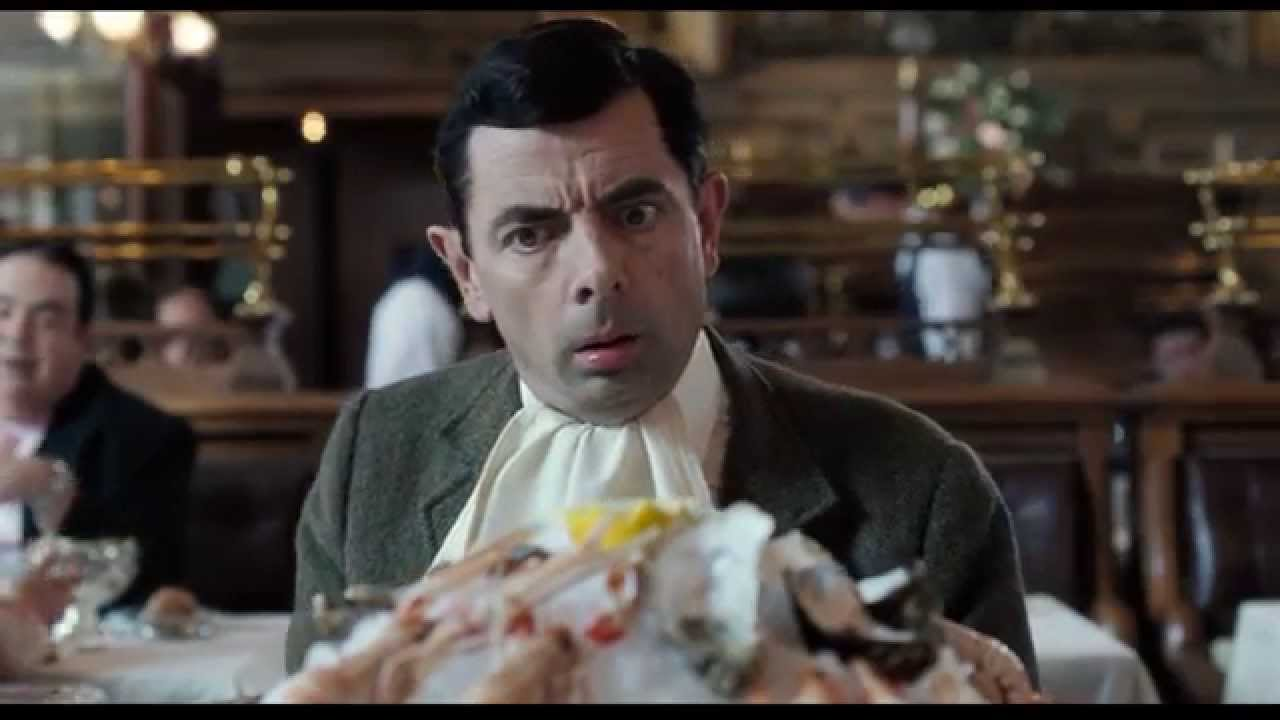

**3. Провести препроцесинг даних для подальшої їх передачі в модель.**

In [237]:
%%writefile /content/drive/MyDrive/ML1/process_bank_marketing.py

"""Препроцесинг UCI Bank Marketing для mid-term проєкту."""

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split   # НОВЕ
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score

UNKNOWN_COLS = ['job', 'marital', 'education', 'default', 'housing', 'loan']

CAT_COLS = ['job', 'education', 'poutcome',
            'age_bin', 'campaign_bin', 'previous_bin']

BIN_COLS = ['pdays_known', 'has_unknown', 'is_single',
            'is_monday', 'default_clean', 'is_cellular']

NUM_COLS = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
            'euribor3m', 'nr.employed']

INPUT_COLS = CAT_COLS + BIN_COLS + NUM_COLS


def add_time_axis(df: pd.DataFrame) -> pd.DataFrame:
    """Номер блоку місяця (1..26) і рік за порядком рядків у файлі.
    Викликати на сирому файлі до будь-якого перемішування."""
    df = df.copy()
    df['period'] = (df['month'] != df['month'].shift()).cumsum()
    df['year'] = np.where(df['period'] <= 7, 2008,
                          np.where(df['period'] <= 17, 2009, 2010))
    return df


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Stateless ознаки: кожна залежить тільки від свого рядка.
    Працює і на нових даних без колонки 'y'."""
    df = df.copy()
    if 'y' in df.columns:
        df['target'] = (df['y'] == 'yes').astype(int)

    df['age_bin'] = pd.cut(df['age'], bins=[-np.inf, 25, 30, 40, 50, 60, 70, np.inf],
                           labels=['<=25', '26-30', '31-40', '41-50', '51-60', '61-70', '71+'])
    df['campaign_bin'] = pd.cut(df['campaign'], bins=[-np.inf, 1, 2, 5, np.inf],
                                labels=['1', '2', '3-5', '6+'])
    df['previous_bin'] = pd.cut(df['previous'], bins=[-np.inf, 0, 1, 2, np.inf],
                                labels=['0', '1', '2', '3+'])

    df['pdays_known']   = (df['pdays'] < 999).astype(int)
    df['has_unknown']   = ((df[UNKNOWN_COLS] == 'unknown').sum(axis=1) > 0).astype(int)
    df['is_single']     = (df['marital'] == 'single').astype(int)
    df['is_monday']     = (df['day_of_week'] == 'mon').astype(int)
    df['default_clean'] = (df['default'] == 'no').astype(int)
    df['is_cellular']   = (df['contact'] == 'cellular').astype(int)
    df['education']     = df['education'].replace('illiterate', 'basic.4y')
    return df


def split_random(df: pd.DataFrame, test_size: float = 0.2,          # НОВЕ
                 random_state: int = 42) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Випадкове стратифіковане розбиття на train і val.
    Підбір гіперпараметрів далі через CV всередині train."""
    train_df, val_df = train_test_split(df, test_size=test_size,
                                        random_state=random_state,
                                        stratify=df['target'])
    return train_df.copy(), val_df.copy()

def split_time(df: pd.DataFrame,
               last_train_period: int = 17) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Часове розбиття: train 2008 і 2009 (блоки 1..17), test 2010 (блоки 18..26).
    Без перемішування і без stratify."""
    train_df = df[df['period'] <= last_train_period]
    test_df  = df[df['period'] >  last_train_period]
    return train_df.copy(), test_df.copy()

def fit_clip_bounds(train_df: pd.DataFrame, cols: list[str]) -> dict:
    """Межі обрізання з train: {колонка: (min, max)}."""
    return {c: (train_df[c].min(), train_df[c].max()) for c in cols}


def apply_clip(df: pd.DataFrame, bounds: dict) -> pd.DataFrame:
    """Обрізати колонки до меж train. Жодного fit усередині."""
    df = df.copy()
    for c, (lo, hi) in bounds.items():
        df[c] = df[c].clip(lo, hi)
    return df


def fit_preprocessor(train_df: pd.DataFrame, kind: str = 'linear') -> dict:
    """Навчити препроцесор ТІЛЬКИ на train.
    kind='linear': обрізання + one-hot + масштабування числових (логістична, kNN).
    kind='tree':   one-hot, числові без змін (дерева)."""
    assert kind in ('linear', 'tree'), kind
    train_df = train_df[INPUT_COLS].copy()

    if kind == 'linear':
        bounds = fit_clip_bounds(train_df, NUM_COLS)
        train_df = apply_clip(train_df, bounds)
        num_step = StandardScaler()
    else:
        bounds = None
        num_step = 'passthrough'

    ct = ColumnTransformer([
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS),
            ('bin', 'passthrough', BIN_COLS),
            ('num', num_step, NUM_COLS)],
        verbose_feature_names_out=False)
    ct.set_output(transform='pandas')
    ct.fit(train_df)
    return {'bounds': bounds, 'ct': ct}


def apply_preprocessor(df: pd.DataFrame, prep: dict) -> pd.DataFrame:
    """Застосувати навчений препроцесор. Жодного fit усередині."""
    df = df[INPUT_COLS].copy()
    if prep['bounds'] is not None:
        df = apply_clip(df, prep['bounds'])
    return prep['ct'].transform(df)


def fit_category_dtypes(train_df: pd.DataFrame, cols: list[str] = CAT_COLS) -> dict:
    """Списки категорій ТІЛЬКИ з train: {колонка: CategoricalDtype}."""
    return {c: pd.CategoricalDtype(categories=sorted(train_df[c].astype(str).unique()))
            for c in cols}


def apply_category_dtypes(df: pd.DataFrame, dtypes: dict) -> pd.DataFrame:
    """Матриця для бустингу: категорії з train, решта без змін.
    Рівень, якого не було в train, стає NaN."""
    df = df[INPUT_COLS].copy()
    for c, dt in dtypes.items():
        df[c] = df[c].astype(str).astype(dt)
    return df


def fit_prep(train_df: pd.DataFrame, kind: str) -> dict:
    """Навчити препроцесор потрібного виду ТІЛЬКИ на train."""
    if kind == 'boost':
        return {'kind': kind, 'dtypes': fit_category_dtypes(train_df)}
    return {'kind': kind, **fit_preprocessor(train_df, kind)}


def apply_prep(df: pd.DataFrame, prep: dict) -> pd.DataFrame:
    """Застосувати навчений препроцесор. Жодного fit усередині."""
    if prep['kind'] == 'boost':
        return apply_category_dtypes(df, prep['dtypes'])
    return apply_preprocessor(df, prep)


def preprocess_data(raw_df: pd.DataFrame, kind: str = 'linear', split: str = 'random',
                    random_state: int = 42, dedup_train: bool = False) -> dict:
    """Повний цикл: ознаки, розбиття, fit на train, матриці train і val.
    kind: 'linear' | 'tree' | 'boost'; split: 'random' | 'time'."""
    df = build_features(add_time_axis(raw_df))

    if split == 'random':
        train_df, val_df = split_random(df, random_state=random_state)
    else:
        train_df, val_df = split_time(df)

    if dedup_train:
        train_df = train_df.drop_duplicates(subset=list(raw_df.columns))

    prep = fit_prep(train_df, kind)
    X_train = apply_prep(train_df, prep)
    X_val   = apply_prep(val_df, prep)

    return {'X_train': X_train, 'train_targets': train_df['target'],
            'X_val': X_val, 'val_targets': val_df['target'],
            'prep': prep, 'input_cols': list(X_train.columns)}


def preprocess_new_data(new_df: pd.DataFrame, prep: dict, input_cols: list[str]) -> pd.DataFrame:
    """Нові сирі дані: ознаки і навчений препроцесор. Жодного fit.
    Колонка 'y' не потрібна."""
    X = apply_prep(build_features(new_df), prep)
    assert list(X.columns) == input_cols, 'колонки не збігаються з train'
    return X


BUSINESS_SHARE = 1000 / 41188   # 1 000 дзвінків на всю базу, 2.43 %


def lift_at_share(y_true, proba, share: float = BUSINESS_SHARE) -> float:
    """Частка позитивів серед топ-share рядків за ймовірністю, поділена на частку в усіх."""
    y = np.asarray(y_true)
    k = max(1, int(round(len(y) * share)))
    top = np.argsort(-np.asarray(proba))[:k]
    return y[top].mean() / y.mean()


def evaluate(y_true, proba, share: float = BUSINESS_SHARE) -> dict:
    """Метрики ранжування. proba = predict_proba(X)[:, 1], ніколи не predict(X)."""
    base = np.mean(y_true)
    ap = average_precision_score(y_true, proba)
    return {'base_rate': base, 'ap': ap, 'ap_lift': ap / base,
            'roc_auc': roc_auc_score(y_true, proba),
            'lift_top': lift_at_share(y_true, proba, share)}

Overwriting /content/drive/MyDrive/ML1/process_bank_marketing.py


In [238]:
import sys, importlib

sys.path.append('/content/drive/MyDrive/ML1')

importlib.invalidate_caches()
import process_bank_marketing as pbm
importlib.reload(pbm)

<module 'process_bank_marketing' from '/content/drive/MyDrive/ML1/process_bank_marketing.py'>

In [239]:
# check
fresh = pd.read_csv(data_dir + 'bank-additional-full.csv', sep=';')
df = pbm.build_features(pbm.add_time_axis(fresh))

for col in ['target', 'age_bin', 'campaign_bin', 'previous_bin', 'pdays_known',
            'has_unknown', 'is_single', 'is_monday', 'default_clean',
            'education', 'period', 'year', 'is_cellular']:
    print(f'{col:14s}', df[col].equals(raw_df[col]))

target         True
age_bin        True
campaign_bin   True
previous_bin   True
pdays_known    True
has_unknown    True
is_single      True
is_monday      True
default_clean  True
education      True
period         True
year           True
is_cellular    True


In [240]:
# check if I included all columns
print(len(pbm.INPUT_COLS))                                    # 17
print(set(pbm.INPUT_COLS) & {'y', 'target', 'duration', 'period', 'year',
                             'row', 'n_unknown', 'month', 'campaign', 'age'})  # set()
print(set(pbm.INPUT_COLS) - set(df.columns))                  # set()

17
set()
set()


In [241]:
# випадкове стратифіковане розбиття, дві частини
train_df, val_df = pbm.split_random(df)

for name, part in [('train', train_df), ('val', val_df)]:
    print(f'{name:6s} рядків {len(part):6d}  позитивів {part["target"].sum():5d}  '
          f'частка {part["target"].mean():.4f}')

train  рядків  32950  позитивів  3712  частка 0.1127
val    рядків   8238  позитивів   928  частка 0.1126


Дані розбито на дві частини, 80% train і 20% val, зі стратифікацією за target. Гіперпараметри підбираються крос-валідацією всередині train, а val залишається недоторканою для фінальної оцінки.

In [242]:
(df.groupby('period')
   .agg(year=('year', 'first'), month=('month', 'first'),
        n=('target', 'size'), yes=('target', 'sum'), rate=('target', 'mean'))
   .assign(n_after=lambda t: t['n'][::-1].cumsum()[::-1],
           yes_after=lambda t: t['yes'][::-1].cumsum()[::-1])
   .loc[12:]
   .round(4))

,year,month,n,yes,rate,n_after,yes_after
period,,,,,,,
12,2009,jul,178,66,0.3708,4249,1945
13,2009,aug,770,264,0.3429,4071,1879
14,2009,sep,267,106,0.3970,3301,1615
15,2009,oct,447,180,0.4027,3034,1509
16,2009,nov,357,168,0.4706,2587,1329
17,2009,dec,172,88,0.5116,2230,1161
18,2010,mar,264,150,0.5682,2058,1073
19,2010,apr,174,97,0.5575,1794,923
20,2010,may,212,122,0.5755,1620,826


Часове розбиття: train складають 2008 і 2009 роки (блоки з 1 по 17), test увесь 2010 рік (блоки з 18 по 26), без перемішування і без стратифікації. Межа за роком, а не посеред нього, щоб train містив початок нового режиму кампанії: з липня 2009 конверсія не опускається нижче 0.34.

Test має 2058 рядків і частку позитивів 0.52 проти 0.09 у train, тому PR AUC двох розбиттів напряму не порівнюються: порівнюю ROC AUC.

Бізнесову метрику на часовому test рахую як lift на тій самій частці бази, що й 1 000 дзвінків від 41 188 рядків, тобто на топ-2.4 %, приблизно 50 рядках test.

In [243]:
train_t, test_t = pbm.split_time(df)

for name, part in [('train_t', train_t), ('test_t', test_t)]:
    print(f'{name:8s} рядків {len(part):6d}  позитивів {part["target"].sum():5d}  '
          f'частка {part["target"].mean():.4f}  блоки {part["period"].min()} по {part["period"].max()}')

assert len(train_t) + len(test_t) == len(df)

train_t  рядків  39130  позитивів  3567  частка 0.0912  блоки 1 по 17
test_t   рядків   2058  позитивів  1073  частка 0.5214  блоки 18 по 26


In [244]:
for col in pbm.NUM_COLS:
    tr_min, tr_max = train_t[col].min(), train_t[col].max()
    out = ((test_t[col] < tr_min) | (test_t[col] > tr_max)).sum()
    print(f'{col:15s} train {tr_min:9.3f} .. {tr_max:9.3f}   '
          f'test {test_t[col].min():9.3f} .. {test_t[col].max():9.3f}   '
          f'поза межами train: {out:4d} з {len(test_t)}')

emp.var.rate    train    -3.400 ..     1.400   test    -1.800 ..    -1.100   поза межами train:    0 з 2058
cons.price.idx  train    92.201 ..    94.465   test    93.369 ..    94.767   поза межами train:  332 з 2058
cons.conf.idx   train   -50.000 ..   -26.900   test   -50.800 ..   -34.600   поза межами train:  128 з 2058
euribor3m       train     0.700 ..     5.045   test     0.634 ..     1.050   поза межами train:  639 з 2058
nr.employed     train  5017.500 ..  5228.100   test  4963.600 ..  5008.700   поза межами train: 2058 з 2058


На часовому test чотири з п'яти макроколонок виходять за межі значень train: nr.employed у всіх 2 058 рядках нижчий за мінімум train, euribor3m у 639, cons.price.idx у 332, cons.conf.idx у 128. Модель на 2010 році передбачає за умов, яких не бачила. Дерева сприймають такі значення як найкрайніше відоме, а лінійна модель і kNN екстраполюють. Тому на часовому розбитті очікую найбільше падіння в логістичної регресії і kNN, а найменше в бустингу.

In [245]:
bounds = pbm.fit_clip_bounds(train_t, pbm.NUM_COLS)
test_t_clip  = pbm.apply_clip(test_t, bounds)
train_t_clip = pbm.apply_clip(train_t, bounds)

# 1. у test нічого не виходить за межі train
for col in pbm.NUM_COLS:
    lo, hi = bounds[col]
    print(f'{col:15s}', ((test_t_clip[col] < lo) | (test_t_clip[col] > hi)).sum())   # усі 0

# 2. train не змінився: його власні межі нічого в ньому не обрізають
print(train_t_clip[pbm.NUM_COLS].equals(train_t[pbm.NUM_COLS]))                  # True

emp.var.rate    0
cons.price.idx  0
cons.conf.idx   0
euribor3m       0
nr.employed     0
True


Для логістичної регресії і kNN числові колонки обрізаю до діапазону train перед масштабуванням. Межі беруться тільки з train. На часовому test це зменшує найдальше значення nr.employed з −3.49 до −2.61 стандартного відхилення, і лінійна модель не екстраполює тренд за межі, яких не бачила.

Для дерев і бустингу обрізання не застосовую: на їхні передбачення воно не впливає.

In [246]:
prep_lin = pbm.fit_preprocessor(train_df, kind='linear')
X_train = pbm.apply_preprocessor(train_df, prep_lin)
X_val   = pbm.apply_preprocessor(val_df, prep_lin)

print(X_train.shape, X_val.shape)
print('NaN:', X_train.isna().sum().sum(), X_val.isna().sum().sum())   # 0 0
print(list(X_train.columns[:5]), '...', list(X_train.columns[-5:]))

(32950, 48) (8238, 48)
NaN: 0 0
['job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management'] ... ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [247]:
prep_tree = pbm.fit_preprocessor(train_df, kind='tree')
X_train_tree = pbm.apply_preprocessor(train_df, prep_tree)
X_val_tree   = pbm.apply_preprocessor(val_df, prep_tree)

print(X_train_tree.shape, X_val_tree.shape)
print('bounds:', prep_tree['bounds'])
print('числові без змін:',
      np.allclose(X_train_tree[pbm.NUM_COLS].to_numpy(),
                  train_df[pbm.NUM_COLS].to_numpy()))
print('ті самі колонки, що в linear:',
      list(X_train_tree.columns) == list(X_train.columns))

(32950, 48) (8238, 48)
bounds: None
числові без змін: True
ті самі колонки, що в linear: True


In [248]:
# 1. випадкове розбиття: скейлер запам'ятав train, а не весь файл
sc = prep_lin['ct'].named_transformers_['num']
print('mean_ = середнє train:   ', np.allclose(sc.mean_, train_df[pbm.NUM_COLS].mean()))   # True
print('mean_ = середнє всього df:', np.allclose(sc.mean_, df[pbm.NUM_COLS].mean()))         # False
print(X_train[pbm.NUM_COLS].mean().round(4).tolist())   # усі 0
print(X_val[pbm.NUM_COLS].mean().round(4).tolist())     # близько 0, але не 0

# 2. часове розбиття: fit тільки на 2008 і 2009
prep_t   = pbm.fit_preprocessor(train_t, kind='linear')
X_test_t = pbm.apply_preprocessor(test_t, prep_t)
print(X_test_t['nr.employed'].describe().round(3))

mean_ = середнє train:    True
mean_ = середнє всього df: False
[-0.0, 0.0, 0.0, -0.0, 0.0]
[0.0045, -0.0019, 0.0064, 0.0083, 0.0094]
count    2058.000
mean       -2.609
std         0.000
min        -2.609
25%        -2.609
50%        -2.609
75%        -2.609
max        -2.609
Name: nr.employed, dtype: float64


Препроцесор навчається тільки на train.
Середнє, яке запам'ятав скейлер, збігається із середнім train, а не всього набору. На val середні числових колонок близькі до нуля, але не дорівнюють йому. На часовому test обрізання робить nr.employed константою: усі рядки 2010 року отримують одне значення, −2.61. Колонка втрачає різницю всередині 2010 року. Вплив цього на метрику я виміряю на кроці 7: логістична регресія з обрізанням і без нього.

In [249]:
dts = pbm.fit_category_dtypes(train_df)
X_train_b = pbm.apply_category_dtypes(train_df, dts)
X_val_b   = pbm.apply_category_dtypes(val_df, dts)

print(X_train_b.shape, X_val_b.shape)                 # 17 колонок
print(X_train_b.dtypes.value_counts())                # category 6, int64 6, float64 5
print('ті самі категорії в train і val:',
      all(list(X_train_b[c].cat.categories) == list(X_val_b[c].cat.categories)
          for c in pbm.CAT_COLS))                     # True
print('NaN у категоріях val:', X_val_b[pbm.CAT_COLS].isna().sum().sum())   # 0

(32950, 17) (8238, 17)
int64       6
float64     5
category    1
category    1
category    1
category    1
category    1
category    1
Name: count, dtype: int64
ті самі категорії в train і val: True
NaN у категоріях val: 0


In [250]:
data = pbm.preprocess_data(fresh, kind='linear')

# 1. обгортка дає те саме, що кроки 3 і 4 вручну
print('X_train як у 3.2:', data['X_train'].equals(X_train))
print('X_val як у 3.2:  ', data['X_val'].equals(X_val))
data_b = pbm.preprocess_data(fresh, kind='boost')
print('бустинг як у 4:  ', data_b['X_train'].equals(X_train_b))

# 2. нові дані без 'y', навіть один рядок
new = fresh.drop(columns='y').head(1)
X_new = pbm.preprocess_new_data(new, data['prep'], data['input_cols'])
print(X_new.shape)
print(X_new[pbm.NUM_COLS].round(3).values)

X_train як у 3.2: True
X_val як у 3.2:   True
бустинг як у 4:   True
(1, 48)
[[0.649 0.722 0.888 0.714 0.333]]


Препроцесинг винесено в модуль process_bank_marketing.py. Функція preprocess_data будує ознаки, розбиває дані і навчає препроцесор тільки на train. Вона готує три види матриць: linear (one-hot, обрізання і масштабування), tree (one-hot без масштабування) і boost (тип category).

Функція preprocess_new_data застосовує навчений препроцесор до нових даних без жодного fit. Обгортки дають ті самі матриці, що й покрокова збірка вище. Один новий рядок без цільової колонки обробляється коректно.

**3.1. Перевірка рішення про дублікати**

Дублікати прибираються лише з train, після розбиття. Обидва варіанти оцінюються на тій самій val, на 10 сідах. Модель: логістична регресія з налаштуваннями за замовчуванням. Різницю AP порівнюю з розкидом AP між сідами.

In [251]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score


def make_model():
    """Фабрика: щоразу нова ненавчена модель."""
    return LogisticRegression(max_iter=1000)


rows = []
for seed in range(10):
    for dedup in (False, True):
        d = pbm.preprocess_data(fresh, kind='linear', random_state=seed, dedup_train=dedup)
        model = make_model().fit(d['X_train'], d['train_targets'])
        proba = model.predict_proba(d['X_val'])[:, 1]
        rows.append({'seed': seed, 'dedup': dedup,
                     'n_train': len(d['X_train']), 'n_val': len(d['X_val']),
                     'ap': average_precision_score(d['val_targets'], proba)})

res = pd.DataFrame(rows)
wide = res.pivot(index='seed', columns='dedup', values='ap')
wide.columns = ['ap_keep', 'ap_dedup']
wide['diff'] = wide['ap_dedup'] - wide['ap_keep']
wide['dropped'] = (res[~res['dedup']].set_index('seed')['n_train']
                   - res[res['dedup']].set_index('seed')['n_train'])
print(wide.round(5))
print()
print('середня різниця AP:     ', round(wide['diff'].mean(), 5))
print('std AP між сідами (шум):', round(wide['ap_keep'].std(), 5))
print('val однакова:', res.groupby('seed')['n_val'].nunique().eq(1).all())

      ap_keep  ap_dedup     diff  dropped
seed                                     
0     0.42861   0.42868  0.00007        7
1     0.45465   0.45453 -0.00012        7
2     0.45480   0.45428 -0.00052       10
3     0.40593   0.40647  0.00054        7
4     0.44965   0.44970  0.00006        8
5     0.44762   0.44764  0.00002        8
6     0.43240   0.43217 -0.00022       10
7     0.43972   0.43972  0.00001        6
8     0.45711   0.45712  0.00001        7
9     0.46864   0.46841 -0.00023        6

середня різниця AP:      -4e-05
std AP між сідами (шум): 0.01793
val однакова: True


Дедуплікація не впливає на якість моделі. Середня різниця AP між двома варіантами становить −0.00004, а розкид AP між сідами 0.018, тобто різниця в 450 разів менша за шум. Знаки різниці змішані: у п'яти сідах дедуплікація трохи краща, у п'яти трохи гірша. Рішення залишити дублікати підтверджене.

З train прибирається від 6 до 10 дублікатів, а не 12. Пара прибирається лише тоді, коли обидві копії потрапили в train. Імовірність цього 0.8 × 0.8 = 0.64, тому очікувано 7.7 рядка. Фактичне середнє 7.6.

Розкид AP між сідами, 0.018, тепер слугує еталоном шуму для всіх наступних порівнянь на цьому розбитті. Різницю між моделями, меншу за це число, я не вважаю доведеною.

**4. Натренувати 4 різні типи моделей машинного навчання.**

**4.1. Метрики оцінки**

Два розбиття мають різну частку позитивів: 0.11 на val і 0.52 на 2010 році. Тому для порівняння розбиттів використовую ROC AUC. AP і lift читаю відносно їхньої стелі, 1 / частка позитивів. Бізнесову метрику рахую як lift на топ-2.43 % рядків, що відповідає 1 000 дзвінкам на всю базу.

In [252]:
y_toy = np.array([1, 0, 0, 1, 0, 0, 0, 0, 1, 0])
p_toy = np.array([0.90, 0.80, 0.10, 0.40, 0.30, 0.20, 0.05, 0.15, 0.70, 0.35])
print(round(pbm.lift_at_share(y_toy, p_toy, 0.2), 3), round(pbm.lift_at_share(y_toy, p_toy, 0.3), 3))

# межі: ідеальна модель і випадкова на val
y_val = data['val_targets']
print(pbm.evaluate(y_val, y_val.to_numpy()))                          # ROC AUC 1.0, lift_top = 1 / частка
print(pbm.evaluate(y_val, np.random.default_rng(0).random(len(y_val))))  # ROC AUC близько 0.5, lift близько 1

1.667 2.222
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(1.0), 'ap_lift': np.float64(8.877155172413794), 'roc_auc': np.float64(1.0), 'lift_top': np.float64(8.877155172413794)}
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(0.11879812387041891), 'ap_lift': np.float64(1.0545893797893438), 'roc_auc': np.float64(0.517838547808859), 'lift_top': np.float64(1.065258620689655)}


**4.2. Ціна майбутнього: логістична регресія на двох розбиттях**

Та сама модель навчається на випадковому розбитті і на часовому. Різниця ROC AUC показує, наскільки випадкове розбиття завищує оцінку. На часовому test окремо порівнюю варіант з обрізанням до меж train і без нього.

In [253]:
def score_row(model_name, split_name, part, y, proba):
    return {'model': model_name, 'split': split_name, 'part': part, **pbm.evaluate(y, proba)}

rows = []

# випадкове розбиття
d_r  = pbm.preprocess_data(fresh, kind='linear', split='random')
lr_r = make_model().fit(d_r['X_train'], d_r['train_targets'])
rows.append(score_row('LR', 'random', 'train', d_r['train_targets'], lr_r.predict_proba(d_r['X_train'])[:, 1]))
rows.append(score_row('LR', 'random', 'val',   d_r['val_targets'],   lr_r.predict_proba(d_r['X_val'])[:, 1]))

# часове розбиття: у словнику ключ 'X_val' тут означає test 2010 року
d_t  = pbm.preprocess_data(fresh, kind='linear', split='time')
lr_t = make_model().fit(d_t['X_train'], d_t['train_targets'])
rows.append(score_row('LR', 'time', 'train',       d_t['train_targets'], lr_t.predict_proba(d_t['X_train'])[:, 1]))
rows.append(score_row('LR', 'time', 'test, clip',  d_t['val_targets'],   lr_t.predict_proba(d_t['X_val'])[:, 1]))

# той самий препроцесор і та сама модель, тільки без обрізання test
prep_noclip   = {**d_t['prep'], 'bounds': None}
X_test_noclip = pbm.apply_prep(test_t, prep_noclip)
rows.append(score_row('LR', 'time', 'test, no clip', test_t['target'], lr_t.predict_proba(X_test_noclip)[:, 1]))

lr_table = pd.DataFrame(rows).round(4)
lr_table

,model,split,part,base_rate,ap,ap_lift,roc_auc,lift_top
0,LR,random,train,0.1127,0.4412,3.9162,0.7823,6.5687
1,LR,random,val,0.1126,0.4554,4.0423,0.7949,6.5691
2,LR,time,train,0.0912,0.3250,3.5651,0.7421,5.9700
3,LR,time,"test, clip",0.5214,0.7252,1.3910,0.7250,1.5344
4,LR,time,"test, no clip",0.5214,0.7229,1.3865,0.7231,1.5344


На випадковому розбитті логістична регресія дає ROC AUC 0.795 на val, на часовому 0.725 на 2010 році. Різниця 0.070 і є ціною того, що випадкове розбиття бачить майбутнє. Усередині часового розбиття падіння від train до test лише 0.017. Отже, випадкова val завищує оцінку, бо змішує періоди з конверсією від 3 до 57 %, а макроколонки легко їх розрізняють. AP між розбиттями не порівнюю: його стеля залежить від частки позитивів, 0.11 на val і 0.52 у 2010 році. Обрізання до меж train змінює ROC AUC на 0.002, це в межах шуму, тому обрізання залишаю.

**4.3. Чотири моделі на двох розбиттях**

Моделі базові, без тюнінгу: тюнінг бустингу буде в пункті 6. Перевіряю два прогнози, записані до запуску. Перший: бустинг виграє в дерева, дерево в логістичної регресії, kNN останній. Другий: на часовому розбитті найбільше падіння в логістичної регресії і kNN, найменше в бустингу.

In [254]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from lightgbm import LGBMClassifier

MODELS = {
    'LR':   ('linear', lambda: LogisticRegression(max_iter=1000)),
    'kNN':  ('linear', lambda: KNeighborsClassifier(n_neighbors=50)),
    'Tree': ('tree',   lambda: DecisionTreeClassifier(max_depth=6, random_state=42)),
    'LGBM': ('boost',  lambda: LGBMClassifier(n_estimators=200, learning_rate=0.05,
                                              random_state=42, verbose=-1)),
}

fitted = {}
rows = []
for name, (kind, factory) in MODELS.items():
    for split in ('random', 'time'):
        d = pbm.preprocess_data(fresh, kind=kind, split=split)
        model = factory().fit(d['X_train'], d['train_targets'])
        fitted[(name, split)] = model
        for part, X, y in [('train', d['X_train'], d['train_targets']),
                           ('val/test', d['X_val'], d['val_targets'])]:
            proba = model.predict_proba(X)[:, 1]
            rows.append({'model': name, 'split': split, 'part': part,
                         **pbm.evaluate(y, proba), 'n_unique': len(np.unique(proba))})

all_table = pd.DataFrame(rows).round(4)

# головне: ROC AUC на val/test і падіння від випадкового розбиття до часового
roc = (all_table[all_table['part'] == 'val/test']
       .pivot(index='model', columns='split', values='roc_auc'))
roc['drop'] = roc['random'] - roc['time']
print(roc.sort_values('random', ascending=False).round(4))

split  random    time    drop
model                        
LGBM   0.8143  0.6888  0.1255
Tree   0.7983  0.6654  0.1329
LR     0.7949  0.7250  0.0699
kNN    0.7905  0.6671  0.1234


In [255]:
lgbm = fitted[('LGBM', 'random')]
print(dict(zip(pbm.INPUT_COLS, lgbm.feature_importances_)))

{'job': np.int32(391), 'education': np.int32(254), 'poutcome': np.int32(285), 'age_bin': np.int32(260), 'campaign_bin': np.int32(194), 'previous_bin': np.int32(191), 'pdays_known': np.int32(102), 'has_unknown': np.int32(122), 'is_single': np.int32(300), 'is_monday': np.int32(235), 'default_clean': np.int32(128), 'is_cellular': np.int32(193), 'emp.var.rate': np.int32(161), 'cons.price.idx': np.int32(416), 'cons.conf.idx': np.int32(376), 'euribor3m': np.int32(2243), 'nr.employed': np.int32(149)}


На випадковій val моделі стоять у порядку: LGBM 0.814, дерево 0.798, логістична регресія 0.795, kNN 0.789. Але лише відрив LGBM більший за ймовірний шум розбиття, різниці між рештою не перевищують 0.006. Другий прогноз не справдився. На 2010 році найменше впала логістична регресія, на 0.070, і стала найкращою моделлю з ROC AUC 0.725. Дерево, kNN і LGBM впали на величину від 0.123 до 0.133. LGBM витрачає 37% поділів на euribor3m, тобто фактично ріже дату на дрібні періоди. На випадковій val ці періоди повторюються, а у 2010 році їх немає. Лінійна модель бачить лише плавний нахил макроколонок і тому краще переноситься в майбутній період.

**4.4. Шум ROC AUC між сідами**

Ті самі чотири моделі на випадковому розбитті з п'ятьма сідами. Різницю між моделями рахую попарно в межах сіда, бо обидві моделі тоді бачать ту саму val. Перевагу вважаю реальною, якщо різниця має той самий знак на всіх сідах.

In [256]:
from sklearn.metrics import roc_auc_score

seed_rows = []
for seed in range(5):
    for name, (kind, factory) in MODELS.items():
        d = pbm.preprocess_data(fresh, kind=kind, split='random', random_state=seed)
        m = factory().fit(d['X_train'], d['train_targets'])
        p = m.predict_proba(d['X_val'])[:, 1]
        seed_rows.append({'seed': seed, 'model': name,
                          'roc_auc': roc_auc_score(d['val_targets'], p)})

seeds = pd.DataFrame(seed_rows).pivot(index='seed', columns='model', values='roc_auc')
print(seeds.round(4))
print()
print(seeds.agg(['mean', 'std']).round(4))
print()

pairs = pd.DataFrame({'LGBM - Tree': seeds['LGBM'] - seeds['Tree'],
                      'Tree - LR':   seeds['Tree'] - seeds['LR'],
                      'LR - kNN':    seeds['LR']   - seeds['kNN']})
print(pairs.agg(['mean', 'std', 'min', 'max']).round(4))

model    LGBM      LR    Tree     kNN
seed                                 
0      0.7991  0.7828  0.7818  0.7655
1      0.8005  0.7808  0.7793  0.7770
2      0.8112  0.7945  0.7962  0.7813
3      0.7927  0.7699  0.7723  0.7608
4      0.8033  0.7849  0.7888  0.7726

model    LGBM      LR    Tree     kNN
mean   0.8014  0.7826  0.7837  0.7714
std    0.0067  0.0088  0.0092  0.0083

      LGBM - Tree  Tree - LR  LR - kNN
mean       0.0177     0.0011    0.0111
std        0.0030     0.0023    0.0050
min        0.0145    -0.0015    0.0038
max        0.0212     0.0040    0.0173


In [257]:
def pick(part, split, col):
    t = all_table[(all_table['part'] == part) & (all_table['split'] == split)]
    return t.set_index('model')[col]

summary = pd.DataFrame({
    'ROC train':              pick('train', 'random', 'roc_auc'),
    'ROC val':                pick('val/test', 'random', 'roc_auc'),
    'ROC val, std 5 сідів':   seeds.std(),
    'ROC test 2010':          pick('val/test', 'time', 'roc_auc'),
    'падіння':                pick('val/test', 'random', 'roc_auc') - pick('val/test', 'time', 'roc_auc'),
    'precision топ-2.43 %, val':  pick('val/test', 'random', 'lift_top') * pick('val/test', 'random', 'base_rate'),
    'precision топ-2.43 %, 2010': pick('val/test', 'time', 'lift_top') * pick('val/test', 'time', 'base_rate'),
}).round(4).sort_values('ROC val', ascending=False)
summary

,ROC train,ROC val,"ROC val, std 5 сідів",ROC test 2010,падіння,"precision топ-2.43 %, val","precision топ-2.43 %, 2010"
model,,,,,,,
LGBM,0.8616,0.8143,0.0067,0.6888,0.1255,0.7397,0.74
Tree,0.7900,0.7983,0.0092,0.6654,0.1329,0.7097,0.76
LR,0.7823,0.7949,0.0088,0.7250,0.0699,0.7397,0.80
kNN,0.8236,0.7905,0.0083,0.6671,0.1234,0.7497,0.82


Попарне порівняння на п'яти сідах розділяє моделі на три групи. LGBM краща за дерево на всіх сідах, у середньому на 0.018. Дерево і логістична регресія нерозрізненні: різниця 0.001 зі змішаним знаком. Логістична регресія краща за kNN на всіх сідах, у середньому на 0.011. Отже, на випадковому розбитті найкраща модель LGBM, а на 2010 році логістична регресія. Precision у топ-2.43 % моделі не розрізняє: на val це 200 рядків, а у 2010 році лише 50.

**4a. Логістична регресія: підбір C**

C обернений до сили регуляризації: менше C означає простішу модель. Підбираю C крос-валідацією на train, 5 стратифікованих фолдів, метрика average precision. Val у підборі не бере участі.

In [258]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_lr = GridSearchCV(LogisticRegression(max_iter=1000),
                       {'C': [0.001, 0.01, 0.1, 1, 10, 100]},
                       scoring='average_precision', cv=cv,
                       return_train_score=True, n_jobs=-1)
grid_lr.fit(d_r['X_train'], d_r['train_targets'])

cv_lr = pd.DataFrame(grid_lr.cv_results_)[['param_C', 'mean_train_score',
                                           'mean_test_score', 'std_test_score']]
print(cv_lr.round(4))
print()
print('сітка від', min(grid_lr.param_grid['C']), 'до', max(grid_lr.param_grid['C']),
      '| найкраще:', grid_lr.best_params_)

best_lr = grid_lr.best_estimator_
print(pbm.evaluate(d_r['val_targets'], best_lr.predict_proba(d_r['X_val'])[:, 1]))

   param_C  mean_train_score  mean_test_score  std_test_score
0    0.001            0.4190           0.4180          0.0115
1    0.010            0.4402           0.4372          0.0112
2    0.100            0.4422           0.4387          0.0141
3    1.000            0.4417           0.4379          0.0147
4   10.000            0.4416           0.4380          0.0147
5  100.000            0.4416           0.4380          0.0147

сітка від 0.001 до 100 | найкраще: {'C': 0.1}
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(0.45622805068432193), 'ap_lift': np.float64(4.05000719993259), 'roc_auc': np.float64(0.7948584691494882), 'lift_top': np.float64(6.569094827586206)}


Підбір C не покращив логістичну регресію. Від C = 0.01 до C = 100 середня AP на фолдах лежить між 0.437 і 0.439, а розкид між фолдами 0.014. Найкраще C = 0.1 перевищує значення за замовчуванням на 0.0008, тобто в межах шуму. Лише C = 0.001 гірше, 0.418, бо модель недонавчена. Train і test майже рівні, отже перенавчання немає: модель обмежує лінійна форма, а не складність. На val AP 0.456 і ROC AUC 0.795, як і без підбору.

**4b. kNN: підбір n_neighbors і weights**

Більше сусідів означає простішу модель. Сітка від 50 до 400 сусідів, з рівними вагами і з вагами за відстанню. Та сама крос-валідація і метрика, що й для логістичної регресії. При weights = 'distance' train score дорівнює 1 за побудовою, бо кожен рядок train є своїм найближчим сусідом.

In [259]:
grid_knn = GridSearchCV(KNeighborsClassifier(),
                        {'n_neighbors': [50, 100, 200, 400],
                         'weights': ['uniform', 'distance']},
                        scoring='average_precision', cv=cv,
                        return_train_score=True, n_jobs=-1)
grid_knn.fit(d_r['X_train'], d_r['train_targets'])

cv_knn = pd.DataFrame(grid_knn.cv_results_)[['param_n_neighbors', 'param_weights',
                                             'mean_train_score', 'mean_test_score',
                                             'std_test_score']]
print(cv_knn.sort_values(['param_weights', 'param_n_neighbors']).round(4))
print()
print('сітка від', min(grid_knn.param_grid['n_neighbors']),
      'до', max(grid_knn.param_grid['n_neighbors']),
      '| найкраще:', grid_knn.best_params_)

best_knn = grid_knn.best_estimator_
proba_knn = best_knn.predict_proba(d_r['X_val'])[:, 1]
print(pbm.evaluate(d_r['val_targets'], proba_knn))
print('різних ймовірностей на val:', len(np.unique(proba_knn)))

   param_n_neighbors param_weights  mean_train_score  mean_test_score  \
1                 50      distance            0.9691           0.2923   
3                100      distance            0.9691           0.2942   
5                200      distance            0.9691           0.2944   
7                400      distance            0.9691           0.2930   
0                 50       uniform            0.4622           0.4256   
2                100       uniform            0.4511           0.4315   
4                200       uniform            0.4400           0.4308   
6                400       uniform            0.4297           0.4245   

   std_test_score  
1          0.0119  
3          0.0118  
5          0.0128  
7          0.0128  
0          0.0092  
2          0.0060  
4          0.0065  
6          0.0071  

сітка від 50 до 400 | найкраще: {'n_neighbors': 100, 'weights': 'uniform'}
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(0.4493239751865841), '

Найкраще k = 100 з рівними вагами, AP на фолдах 0.432. Від 50 до 400 сусідів результат майже не змінюється: різниця 0.007 при розкиді між фолдами близько 0.007. Ваги за відстанню значно гірші, 0.29. Причина в дискретному просторі ознак: багато клієнтів мають однакові вектори ознак, і тоді голосують лише точні копії, а не всі 100 сусідів. З тієї ж причини train при вагах за відстанню дорівнює 0.969, а не 1. На val kNN дає ROC AUC 0.794, як і логістична регресія.

**4c. Дерево рішень: підбір max_depth і min_samples_leaf**

Більша глибина ускладнює модель, більший мінімум рядків у листі спрощує її. Два параметри впливають один на одного, тому після підбору перевіряю справжню глибину і кількість листів найкращого дерева. Матриця без масштабування.

In [260]:
d_tree = pbm.preprocess_data(fresh, kind='tree', split='random')

grid_tree = GridSearchCV(DecisionTreeClassifier(random_state=42),
                         {'max_depth': [3, 4, 5, 6, 8, 10, 12],
                          'min_samples_leaf': [1, 20, 50, 100, 200]},
                         scoring='average_precision', cv=cv,
                         return_train_score=True, n_jobs=-1)
grid_tree.fit(d_tree['X_train'], d_tree['train_targets'])

cv_tree = pd.DataFrame(grid_tree.cv_results_)
print(cv_tree.pivot(index='param_max_depth', columns='param_min_samples_leaf',
                    values='mean_test_score').round(4))
print()
best_row = cv_tree.loc[grid_tree.best_index_]
print('найкраще:', grid_tree.best_params_,
      '| test', round(best_row['mean_test_score'], 4),
      '| std', round(best_row['std_test_score'], 4),
      '| train', round(best_row['mean_train_score'], 4))
print('сітка max_depth від 3 до 12, min_samples_leaf від 1 до 200')

best_tree = grid_tree.best_estimator_
print('справжня глибина:', best_tree.get_depth(), '| листів:', best_tree.get_n_leaves())
print(pbm.evaluate(d_tree['val_targets'], best_tree.predict_proba(d_tree['X_val'])[:, 1]))

param_min_samples_leaf     1       20      50      100     200
param_max_depth                                               
3                       0.3666  0.3666  0.3666  0.3666  0.3741
4                       0.3948  0.3954  0.3964  0.3977  0.3987
5                       0.4078  0.4145  0.4149  0.4127  0.4114
6                       0.4122  0.4224  0.4229  0.4243  0.4202
8                       0.3969  0.4344  0.4327  0.4334  0.4263
10                      0.3653  0.4335  0.4361  0.4372  0.4276
12                      0.3243  0.4303  0.4374  0.4383  0.4283

найкраще: {'max_depth': 12, 'min_samples_leaf': 100} | test 0.4383 | std 0.0084 | train 0.4703
сітка max_depth від 3 до 12, min_samples_leaf від 1 до 200
справжня глибина: 12 | листів: 163
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(0.46613750795270603), 'ap_lift': np.float64(4.1379749897784395), 'roc_auc': np.float64(0.8111316424123779), 'lift_top': np.float64(6.702252155172413)}


In [261]:
grid_tree2 = GridSearchCV(DecisionTreeClassifier(random_state=42),
                          {'max_depth': [10, 12, 14, 16, 20, None],
                           'min_samples_leaf': [50, 100, 150, 200, 300]},
                          scoring='average_precision', cv=cv,
                          return_train_score=True, n_jobs=-1)
grid_tree2.fit(d_tree['X_train'], d_tree['train_targets'])

cv_tree2 = pd.DataFrame(grid_tree2.cv_results_)
cv_tree2['param_max_depth'] = cv_tree2['param_max_depth'].fillna('None').astype(str)
print(cv_tree2.pivot(index='param_max_depth', columns='param_min_samples_leaf',
                     values='mean_test_score').round(4))
print()
best_row2 = cv_tree2.loc[grid_tree2.best_index_]
print('найкраще:', grid_tree2.best_params_,
      '| test', round(best_row2['mean_test_score'], 4),
      '| std', round(best_row2['std_test_score'], 4),
      '| train', round(best_row2['mean_train_score'], 4))

best_tree = grid_tree2.best_estimator_
print('справжня глибина:', best_tree.get_depth(), '| листів:', best_tree.get_n_leaves())
print(pbm.evaluate(d_tree['val_targets'], best_tree.predict_proba(d_tree['X_val'])[:, 1]))

param_min_samples_leaf     50      100     150     200     300
param_max_depth                                               
10                      0.4361  0.4372  0.4353  0.4276  0.4193
12                      0.4374  0.4383  0.4356  0.4283  0.4205
14                      0.4377  0.4385  0.4361  0.4288  0.4206
16                      0.4368  0.4389  0.4363  0.4288  0.4207
20                      0.4367  0.4390  0.4364  0.4288  0.4207
None                    0.4366  0.4391  0.4364  0.4288  0.4207

найкраще: {'max_depth': None, 'min_samples_leaf': 100} | test 0.4391 | std 0.0097 | train 0.4753
справжня глибина: 20 | листів: 241
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(0.46504096993868776), 'ap_lift': np.float64(4.1282408516755495), 'roc_auc': np.float64(0.8048742717816879), 'lift_top': np.float64(6.702252155172413)}


Перша сітка дала найкраще значення на її краю, max_depth = 12, тому я розширила сітку. Після глибини 12 результат майже не змінюється: при 100 рядках у листі AP на фолдах від 0.437 до 0.439, а розкид між фолдами 0.010. Після певної глибини дерево обмежує вже мінімум рядків у листі, і без обмеження глибини воно саме зупиняється на глибині 20. Найкраще значення min_samples_leaf = 100 стоїть всередині сітки. На плато я обираю найпростіше дерево: max_depth = 10, min_samples_leaf = 100. Воно відстає від формально найкращого на 0.002, тобто в п'ять разів менше за шум.

In [262]:
final_tree = DecisionTreeClassifier(max_depth=10, min_samples_leaf=100, random_state=42)
final_tree.fit(d_tree['X_train'], d_tree['train_targets'])

print('справжня глибина:', final_tree.get_depth(), '| листів:', final_tree.get_n_leaves())
print(pbm.evaluate(d_tree['val_targets'], final_tree.predict_proba(d_tree['X_val'])[:, 1]))

справжня глибина: 10 | листів: 118
{'base_rate': np.float64(0.11264870114105366), 'ap': np.float64(0.4655915595664096), 'ap_lift': np.float64(4.133128521237158), 'roc_auc': np.float64(0.8147050715835653), 'lift_top': np.float64(6.746637931034482)}


**5. Таблиця порівняння якості моделей**

Нижче фінальне порівняння чотирьох моделей: гіперпараметри, метрики на train і val, ROC AUC на 2010 році і коментар до кожної моделі.

**4e. Фінальне порівняння чотирьох моделей**

Кожна модель має гіперпараметри з крос-валідації: логістична регресія C = 0.1, kNN 100 сусідів, дерево глибиною 10 з мінімумом 100 рядків у листі. LGBM залишається базовим, його тюнінг у пункті 6. Метрики усереднені по п'яти сідах випадкового розбиття, окремо ROC AUC на 2010 році.

In [263]:
TUNED = {
    'LR':   ('linear', 'C=0.1',
             lambda: LogisticRegression(C=0.1, max_iter=1000)),
    'kNN':  ('linear', 'n_neighbors=100, uniform',
             lambda: KNeighborsClassifier(n_neighbors=100)),
    'Tree': ('tree',   'max_depth=10, min_samples_leaf=100',
             lambda: DecisionTreeClassifier(max_depth=10, min_samples_leaf=100, random_state=42)),
    'LGBM': ('boost',  'n_estimators=200, learning_rate=0.05 (без тюнінгу)',
             lambda: LGBMClassifier(n_estimators=200, learning_rate=0.05,
                                    random_state=42, verbose=-1)),
}

rows, roc_2010 = [], {}
for name, (kind, params, factory) in TUNED.items():
    for seed in range(5):
        d = pbm.preprocess_data(fresh, kind=kind, split='random', random_state=seed)
        m = factory().fit(d['X_train'], d['train_targets'])
        p_tr = m.predict_proba(d['X_train'])[:, 1]
        p_va = m.predict_proba(d['X_val'])[:, 1]
        rows.append({'model': name, 'seed': seed,
                     'ap_train':  average_precision_score(d['train_targets'], p_tr),
                     'ap_val':    average_precision_score(d['val_targets'], p_va),
                     'roc_train': roc_auc_score(d['train_targets'], p_tr),
                     'roc_val':   roc_auc_score(d['val_targets'], p_va)})
    d = pbm.preprocess_data(fresh, kind=kind, split='time')
    m = factory().fit(d['X_train'], d['train_targets'])
    roc_2010[name] = roc_auc_score(d['val_targets'], m.predict_proba(d['X_val'])[:, 1])

final = pd.DataFrame(rows)
table5 = final.groupby('model').agg(
    ap_train=('ap_train', 'mean'), ap_val=('ap_val', 'mean'), ap_val_std=('ap_val', 'std'),
    roc_train=('roc_train', 'mean'), roc_val=('roc_val', 'mean'), roc_val_std=('roc_val', 'std'))
table5['roc_2010'] = pd.Series(roc_2010)
table5['гіперпараметри'] = pd.Series({k: v[1] for k, v in TUNED.items()})
table5 = table5.sort_values('ap_val', ascending=False)
print(table5.round(4).to_string())
print()

w = final.pivot(index='seed', columns='model', values='roc_val')
pairs5 = pd.DataFrame({'LGBM - Tree': w['LGBM'] - w['Tree'],
                       'Tree - LR':   w['Tree'] - w['LR'],
                       'LR - kNN':    w['LR']   - w['kNN']})
print(pairs5.agg(['mean', 'std', 'min', 'max']).round(4))

       ap_train  ap_val  ap_val_std  roc_train  roc_val  roc_val_std  roc_2010                                      гіперпараметри
model                                                                                                                             
LGBM     0.5926  0.4746      0.0163     0.8632   0.8014       0.0067    0.6888  n_estimators=200, learning_rate=0.05 (без тюнінгу)
Tree     0.4726  0.4494      0.0199     0.8146   0.7908       0.0068    0.6710                  max_depth=10, min_samples_leaf=100
LR       0.4462  0.4395      0.0211     0.7840   0.7823       0.0088    0.7270                                               C=0.1
kNN      0.4584  0.4347      0.0157     0.8122   0.7787       0.0100    0.6704                            n_neighbors=100, uniform

      LGBM - Tree  Tree - LR  LR - kNN
mean       0.0105     0.0086    0.0036
std        0.0022     0.0036    0.0033
min        0.0069     0.0057    0.0008
max        0.0128     0.0132    0.0092


In [264]:
table5['коментар'] = pd.Series({
    'LGBM': ('Найкраща модель на випадковому розбитті: ROC AUC 0.801, краща за дерево на всіх п\'яти сідах. '
             'Але вона перенавчена: AP на train 0.593, на val 0.475. '
             'На 2010 році лише 0.689, бо 37 % поділів припадає на euribor3m, тобто фактично на дату. '
             'Далі: тюнінг у пункті 6 у бік регуляризації і перевірка без euribor3m.'),
    'Tree': ('Друга модель: ROC AUC 0.791, після підбору глибини краща за логістичну регресію на всіх сідах. '
             'Перенавчення помірне: AP 0.473 на train, 0.449 на val. '
             'На 2010 році 0.671. '
             'Корисна, щоб пояснити замовнику сегменти клієнтів, але як основна модель поступається бустингу.'),
    'LR':   ('ROC AUC 0.782, перенавчення немає: AP 0.446 на train, 0.440 на val. Підбір C нічого не змінив. '
             'Найкраще переноситься на майбутній період: 0.727 на 2010 році проти 0.671 до 0.689 в інших моделей. '
             'Ідея: додати взаємодії ознак, щоб отримати нелінійність і зберегти стійкість у часі.'),
    'kNN':  ('Найслабша модель: ROC AUC 0.779, але від логістичної регресії відстає лише на 0.004, тобто практично рівна. '
             'Повільна на передбаченні. Ваги за відстанню не працюють через дискретний простір ознак. '
             'На 2010 році 0.671. Використовувати не варто. '
             'Ідея: перевірити, як вага числових колонок відносно бінарних впливає на відстань.'),
})

pd.set_option('display.max_colwidth', None)
table5.round(4)

,ap_train,ap_val,ap_val_std,roc_train,roc_val,roc_val_std,roc_2010,гіперпараметри,коментар
model,,,,,,,,,
LGBM,0.5926,0.4746,0.0163,0.8632,0.8014,0.0067,0.6888,"n_estimators=200, learning_rate=0.05 (без тюнінгу)","Найкраща модель на випадковому розбитті: ROC AUC 0.801, краща за дерево на всіх п'яти сідах. Але вона перенавчена: AP на train 0.593, на val 0.475. На 2010 році лише 0.689, бо 37 % поділів припадає на euribor3m, тобто фактично на дату. Далі: тюнінг у пункті 6 у бік регуляризації і перевірка без euribor3m."
Tree,0.4726,0.4494,0.0199,0.8146,0.7908,0.0068,0.6710,"max_depth=10, min_samples_leaf=100","Друга модель: ROC AUC 0.791, після підбору глибини краща за логістичну регресію на всіх сідах. Перенавчення помірне: AP 0.473 на train, 0.449 на val. На 2010 році 0.671. Корисна, щоб пояснити замовнику сегменти клієнтів, але як основна модель поступається бустингу."
LR,0.4462,0.4395,0.0211,0.7840,0.7823,0.0088,0.7270,C=0.1,"ROC AUC 0.782, перенавчення немає: AP 0.446 на train, 0.440 на val. Підбір C нічого не змінив. Найкраще переноситься на майбутній період: 0.727 на 2010 році проти 0.671 до 0.689 в інших моделей. Ідея: додати взаємодії ознак, щоб отримати нелінійність і зберегти стійкість у часі."
kNN,0.4584,0.4347,0.0157,0.8122,0.7787,0.0100,0.6704,"n_neighbors=100, uniform","Найслабша модель: ROC AUC 0.779, але від логістичної регресії відстає лише на 0.004, тобто практично рівна. Повільна на передбаченні. Ваги за відстанню не працюють через дискретний простір ознак. На 2010 році 0.671. Використовувати не варто. Ідея: перевірити, як вага числових колонок відносно бінарних впливає на відстань."


На випадковому розбитті моделі стоять у порядку LGBM, дерево, логістична регресія, kNN, і кожна перевага підтверджена на всіх п'яти сідах. Різниця між логістичною регресією і kNN дуже мала, 0.004, тому ці дві моделі я вважаю практично рівними. На 2010 році порядок перевертається: найкраща логістична регресія, 0.727, а решта моделей від 0.671 до 0.689. Для рішення, яке працюватиме на майбутніх кампаніях, це важливіше за перемогу на випадковій val. LGBM має найбільший розрив між train і val, тому в пункті 6 я підбираю гіперпараметри в бік регуляризації.

**6. Тюнінг LGBM: Randomized Search і Hyperopt**

Обидва методи отримують той самий простір пошуку, ті самі п'ять фолдів і по 40 спроб. Learning rate фіксований на 0.05, бо разом з кількістю дерев він утворює хребет рівних рішень. Простір веде в бік регуляризації, бо базова модель перенавчена: AP 0.593 на train проти 0.475 на val.

In [265]:
from sklearn.model_selection import cross_val_score

d_b = pbm.preprocess_data(fresh, kind='boost', split='random')

base_lgbm = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=42, verbose=-1)
base_cv = cross_val_score(base_lgbm, d_b['X_train'], d_b['train_targets'],
                          scoring='average_precision', cv=cv, n_jobs=-1)
print('база: AP на фолдах', base_cv.round(4), '| середнє', round(base_cv.mean(), 4),
      '| std', round(base_cv.std(), 4))

база: AP на фолдах [0.4876 0.4614 0.4594 0.4606 0.4526] | середнє 0.4643 | std 0.012


**6.1. Randomized Search**

40 випадкових точок простору, кожна на тих самих п'яти фолдах. Метрика average precision. Після пошуку перевіряю, чи не стоїть найкраще значення на краю діапазону, і порівнюю виграш з розкидом між фолдами.

In [266]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

BOUNDS = {'n_estimators': (100, 800), 'num_leaves': (3, 63),
          'min_child_samples': (20, 400), 'reg_lambda': (0.01, 10),
          'colsample_bytree': (0.5, 1.0), 'subsample': (0.6, 1.0)}

space_rs = {'n_estimators':      randint(100, 801),
            'num_leaves':        randint(3, 64),
            'min_child_samples': randint(20, 401),
            'reg_lambda':        loguniform(0.01, 10),
            'colsample_bytree':  uniform(0.5, 0.5),    # від 0.5 до 1.0
            'subsample':         uniform(0.6, 0.4)}    # від 0.6 до 1.0


def lgbm_factory(**params):
    """Фабрика LGBM: фіксовані налаштування плюс параметри з пошуку."""
    return LGBMClassifier(learning_rate=0.05, subsample_freq=1, random_state=42,
                          verbose=-1, n_jobs=1, **params)


def edge_report(best: dict) -> None:
    """Позиція кожного найкращого значення в діапазоні: 0 нижній край, 1 верхній."""
    for p, (lo, hi) in BOUNDS.items():
        v = best[p]
        pos = ((np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo)) if p == 'reg_lambda'
               else (v - lo) / (hi - lo))
        flag = '  <-- КРАЙ' if pos < 0.05 or pos > 0.95 else ''
        print(f'{p:18s} {v:10.4f}  від {lo} до {hi}  позиція {pos:.2f}{flag}')

In [267]:
# перший запуск: num_leaves від 7, як у початковому просторі
space_rs_v1 = {**space_rs, 'num_leaves': randint(7, 64)}

rs_lgbm_v1 = RandomizedSearchCV(lgbm_factory(), space_rs_v1, n_iter=40,
                                scoring='average_precision', cv=cv, random_state=42,
                                return_train_score=True, n_jobs=-1)
rs_lgbm_v1.fit(d_b['X_train'], d_b['train_targets'])

r1 = pd.DataFrame(rs_lgbm_v1.cv_results_).loc[rs_lgbm_v1.best_index_]
print(f"RS v1: test {r1['mean_test_score']:.4f}  std {r1['std_test_score']:.4f}  "
      f"train {r1['mean_train_score']:.4f}")
print(rs_lgbm_v1.best_params_)
print('num_leaves', rs_lgbm_v1.best_params_['num_leaves'], 'при нижній межі 7')

RS v1: test 0.4719  std 0.0153  train 0.5173
{'colsample_bytree': np.float64(0.8776807051588262), 'min_child_samples': 73, 'n_estimators': 205, 'num_leaves': 10, 'reg_lambda': np.float64(0.035856126103453984), 'subsample': np.float64(0.9878338511058234)}
num_leaves 10 при нижній межі 7


Перший запуск Randomized Search дав AP 0.472 проти 0.464 у бази. Виграш 0.008 менший за розкид між фолдами, 0.012. Модель обрала простіші дерева: 10 листів і 73 рядки в листі. Розрив між train і test скоротився до 0.045. Значення num_leaves лежить майже на нижній межі простору, тому я розширюю діапазон донизу до 3 і повторюю пошук. Subsample біля 1.0 стоїть на природній межі, і його не розширюю.

In [268]:
rs_lgbm = RandomizedSearchCV(lgbm_factory(), space_rs, n_iter=40,
                             scoring='average_precision', cv=cv, random_state=42,
                             return_train_score=True, n_jobs=-1)
rs_lgbm.fit(d_b['X_train'], d_b['train_targets'])

rs_res = pd.DataFrame(rs_lgbm.cv_results_)
rs_best = rs_res.loc[rs_lgbm.best_index_]
print('subsample_freq у моделі:', rs_lgbm.best_estimator_.get_params()['subsample_freq'])   # 1
print(f"RS:   test {rs_best['mean_test_score']:.4f}  std {rs_best['std_test_score']:.4f}  "
      f"train {rs_best['mean_train_score']:.4f}")
print(f"база: test {base_cv.mean():.4f}  std {base_cv.std():.4f}")
print(f"виграш {rs_best['mean_test_score'] - base_cv.mean():.4f}")
print()
edge_report(rs_lgbm.best_params_)

subsample_freq у моделі: 1
RS:   test 0.4691  std 0.0172  train 0.5440
база: test 0.4643  std 0.0120
виграш 0.0048

n_estimators         185.0000  від 100 до 800  позиція 0.12
num_leaves            30.0000  від 3 до 63  позиція 0.45
min_child_samples    262.0000  від 20 до 400  позиція 0.64
reg_lambda             6.1531  від 0.01 до 10  позиція 0.93
colsample_bytree       0.7994  від 0.5 до 1.0  позиція 0.60
subsample              0.9232  від 0.6 до 1.0  позиція 0.81


In [269]:
rs_v2 = {'best_params': rs_lgbm.best_params_, 'test': rs_best['mean_test_score'],
         'std': rs_best['std_test_score'], 'train': rs_best['mean_train_score']}

Після розширення простору найкраща точка змінилася: 30 листів, 262 рядки в листі і сильний L2-штраф, reg_lambda 6.2. AP 0.469, тобто майже як у першому запуску, 0.472. Різниця 0.003 набагато менша за розкид між фолдами, 0.017. Отже, простір має плато: малі дерева і великі листи зі штрафом дають однакову якість. Randomized Search не знайшов виграшу над базою, більшого за шум: від 0.005 до 0.008 при розкиді від 0.012 до 0.017. Тюнінг зменшує перенавчення, але майже не покращує якість на val.

**6.2. Hyperopt: байєсівська оптимізація, TPE**

Той самий простір, ті самі п'ять фолдів і 40 спроб, що й у Randomized Search. Перші приблизно 20 спроб TPE обирає випадково, далі вчиться на попередніх результатах. Простір має плато, тому велика перевага TPE над випадковим пошуком не очікується.

In [270]:
# якщо імпорт падає: !pip install hyperopt
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK, space_eval
from hyperopt.pyll import scope
from sklearn.model_selection import cross_validate

space_hp = {
    'n_estimators':      scope.int(hp.quniform('n_estimators', 100, 800, 1)),
    'num_leaves':        scope.int(hp.quniform('num_leaves', 3, 63, 1)),
    'min_child_samples': scope.int(hp.quniform('min_child_samples', 20, 400, 1)),
    'reg_lambda':        hp.loguniform('reg_lambda', np.log(0.01), np.log(10)),
    'colsample_bytree':  hp.uniform('colsample_bytree', 0.5, 1.0),
    'subsample':         hp.uniform('subsample', 0.6, 1.0),
}


def objective(params):
    cvr = cross_validate(lgbm_factory(**params), d_b['X_train'], d_b['train_targets'],
                         scoring='average_precision', cv=cv,
                         return_train_score=True, n_jobs=-1)
    return {'loss': -cvr['test_score'].mean(), 'status': STATUS_OK,
            'std': cvr['test_score'].std(), 'train': cvr['train_score'].mean()}


trials = Trials()
best_raw = fmin(objective, space_hp, algo=tpe.suggest, max_evals=40,
                trials=trials, rstate=np.random.default_rng(42))
hp_best_params = space_eval(space_hp, best_raw)   # цілі числа замість 205.0

hp_best = trials.best_trial['result']
print(f"HP:   test {-hp_best['loss']:.4f}  std {hp_best['std']:.4f}  train {hp_best['train']:.4f}")
print(f"RS:   test {rs_v2['test']:.4f}  std {rs_v2['std']:.4f}  train {rs_v2['train']:.4f}")
print(f"база: test {base_cv.mean():.4f}  std {base_cv.std():.4f}")
print(f"виграш над базою {-hp_best['loss'] - base_cv.mean():.4f}")
print()
edge_report(hp_best_params)

100%|██████████| 40/40 [08:35<00:00, 12.88s/trial, best loss: -0.47267422797536274]
HP:   test 0.4727  std 0.0166  train 0.5547
RS:   test 0.4691  std 0.0172  train 0.5440
база: test 0.4643  std 0.0120
виграш над базою 0.0083

n_estimators         406.0000  від 100 до 800  позиція 0.44
num_leaves            11.0000  від 3 до 63  позиція 0.13
min_child_samples     57.0000  від 20 до 400  позиція 0.10
reg_lambda             0.2111  від 0.01 до 10  позиція 0.44
colsample_bytree       0.5593  від 0.5 до 1.0  позиція 0.12
subsample              0.8763  від 0.6 до 1.0  позиція 0.69


Hyperopt знайшов AP 0.473 на фолдах, Randomized Search 0.469 і 0.472 у двох запусках, база 0.464. Усі три пошуки лежать у межах 0.004, а розкид між фолдами близько 0.017. Отже, жоден метод не переміг: обидва знаходять одне плато. Виграш над базою, 0.008, удвічі менший за шум. Hyperopt прийшов до того самого рецепту, що й перший запуск Randomized Search: малі дерева з 11 листами і 57 рядками в листі. Жоден параметр не стоїть на краю простору. Байєсівська оптимізація не дала переваги, бо на плато їй нема на що вчитися, і працювала вдвічі довше.

**6.3. Перевірка підібраних конфігурацій на val і на 2010 році**

Чотири конфігурації LGBM: база, два запуски Randomized Search і Hyperopt. Чиста оцінка: val сіду 42, яка не брала участі в тюнінгу. Додатково п'ять сідів попарно з базою і часовий test 2010 року. Ці дві оцінки трохи оптимістичні для підібраних конфігурацій, бо train сіду 42, на якому йшов тюнінг, містив частину цих рядків.

In [271]:
CONFIGS = {'база':  {'n_estimators': 200},
           'RS v1': rs_lgbm_v1.best_params_,
           'RS v2': rs_lgbm.best_params_,
           'HP':    hp_best_params}

clean, seed_rows, t2010 = {}, [], {}
for name, params in CONFIGS.items():
    # чиста val сіду 42
    m = lgbm_factory(**params).fit(d_b['X_train'], d_b['train_targets'])
    clean[name] = pbm.evaluate(d_b['val_targets'], m.predict_proba(d_b['X_val'])[:, 1])
    # 5 сідів
    for seed in range(5):
        d = pbm.preprocess_data(fresh, kind='boost', split='random', random_state=seed)
        m = lgbm_factory(**params).fit(d['X_train'], d['train_targets'])
        seed_rows.append({'config': name, 'seed': seed,
                          'roc': roc_auc_score(d['val_targets'], m.predict_proba(d['X_val'])[:, 1])})
    # 2010 рік
    d = pbm.preprocess_data(fresh, kind='boost', split='time')
    m = lgbm_factory(**params).fit(d['X_train'], d['train_targets'])
    t2010[name] = roc_auc_score(d['val_targets'], m.predict_proba(d['X_val'])[:, 1])

table6 = pd.DataFrame(clean).T[['ap', 'roc_auc', 'lift_top']]
table6.columns = ['AP val 42', 'ROC val 42', 'lift топ-2.43 %']
table6['ROC 2010'] = pd.Series(t2010)
print(table6.round(4))
print()

w6 = pd.DataFrame(seed_rows).pivot(index='seed', columns='config', values='roc')
diff6 = w6[['RS v1', 'RS v2', 'HP']].sub(w6['база'], axis=0)
print('ROC AUC мінус база, 5 сідів:')
print(diff6.agg(['mean', 'std', 'min', 'max']).round(4))
print()
print('для порівняння: LR на 2010 році 0.7270')

       AP val 42  ROC val 42  lift топ-2.43 %  ROC 2010
база      0.4935      0.8143           6.5691    0.6888
RS v1     0.4893      0.8162           6.6135    0.7075
RS v2     0.4906      0.8170           6.7910    0.6867
HP        0.4934      0.8153           6.5691    0.6815

ROC AUC мінус база, 5 сідів:
config   RS v1   RS v2      HP
mean    0.0032 -0.0007  0.0026
std     0.0019  0.0010  0.0017
min     0.0012 -0.0017  0.0006
max     0.0050  0.0009  0.0043

для порівняння: LR на 2010 році 0.7270


На чистій val сіду 42 підібрані конфігурації не перевершують базу: AP від 0.489 до 0.493 проти 0.494. На п'яти сідах дві конфігурації з малими деревами, RS v1 і Hyperopt, стабільно кращі за базу, але лише на 0.003 ROC AUC. Ця оцінка ще й трохи оптимістична, бо тюнінг бачив частину цих рядків. На 2010 році жодна конфігурація LGBM не наближається до логістичної регресії: від 0.682 до 0.708 проти 0.727. Регуляризація зменшує перенавчення, але не змінює того, що модель вивчає: вона ріже час через euribor3m. Як фінальну модель бустингу я обираю RS v1, найпростішу на плато: 205 дерев по 10 листів.

Загальний висновок пункту 6: обидва методи тюнінгу знайшли одне плато, і виграш над базою менший за шум. Randomized Search виявився не гіршим за Hyperopt і працював удвічі швидше.

**7. Важливість ознак для найкращої моделі**

Фінальна модель: LGBM з першого запуску Randomized Search, 205 дерев по 10 листів. Порівнюю два типи важливості: split рахує кількість поділів за колонкою, gain рахує, наскільки ці поділи зменшили помилку. Split завищує неперервні колонки, бо в них багато можливих порогів.

In [272]:
final_lgbm = lgbm_factory(**rs_lgbm_v1.best_params_)
final_lgbm.fit(d_b['X_train'], d_b['train_targets'])

booster = final_lgbm.booster_
imp = pd.DataFrame({'gain':  booster.feature_importance('gain'),
                    'split': booster.feature_importance('split')},
                   index=booster.feature_name())
imp['gain, %']  = (100 * imp['gain']  / imp['gain'].sum()).round(1)
imp['split, %'] = (100 * imp['split'] / imp['split'].sum()).round(1)
imp = imp.sort_values('gain', ascending=False)
print(imp[['gain, %', 'split, %']])
print()
print('сума split:', imp['split'].sum(), '| очікувано 205 дерев × 9 поділів =', 205 * 9)

                gain, %  split, %
nr.employed        47.1       3.5
euribor3m          22.7      30.6
cons.conf.idx       7.6      10.4
pdays_known         4.7       3.1
poutcome            3.9       5.1
cons.price.idx      3.3       7.7
emp.var.rate        2.5       3.0
job                 1.7       9.0
age_bin             1.6       5.3
is_cellular         1.5       3.8
is_monday           0.9       3.6
campaign_bin        0.9       4.6
education           0.7       4.6
default_clean       0.5       2.0
previous_bin        0.3       1.7
is_single           0.2       1.4
has_unknown         0.1       0.8

сума split: 1845 | очікувано 205 дерев × 9 поділів = 1845


Gain і split розходяться. nr.employed має 47 % gain при лише 3.5 % поділів: кілька дуже сильних поділів відділяють період низької зайнятості з високою конверсією. euribor3m має 31 % поділів і 23 % gain: модель ріже його на дрібні проміжки, тобто фактично ріже дату. job має 9 % поділів, але лише 1.7 % gain, це упередження split до колонок з багатьма рівнями. Разом п'ять макроколонок дають 83 % gain, а ознаки клієнта менше 17 %. Мій прогноз справдився частково. Макроблок і pdays_known справді в топі, а pdays_known, poutcome і previous_bin поділили важливість, як я очікувала. Але is_cellular лише десятий: його ефект змішаний з періодом, і період уже несуть макроколонки.

**7.1. Permutation importance на val**

Перемішую колонку у val і рахую, наскільки падає AP. Це показує, що модель справді використовує на нових даних. Корельовані колонки підміняють одна одну, тому окремо перемішую цілі блоки: макроколонки, історію контактів і ознаки клієнта та дзвінка.

In [273]:
from sklearn.inspection import permutation_importance

X_vb, y_vb = d_b['X_val'], d_b['val_targets']
ap_full = average_precision_score(y_vb, final_lgbm.predict_proba(X_vb)[:, 1])
print('AP на val без перемішування:', round(ap_full, 4))

# 1. окремі колонки
pi = permutation_importance(final_lgbm, X_vb, y_vb, scoring='average_precision',
                            n_repeats=10, random_state=42, n_jobs=-1)
pi_df = (pd.DataFrame({'падіння AP': pi.importances_mean, 'std': pi.importances_std},
                      index=X_vb.columns)
           .sort_values('падіння AP', ascending=False))
print(pi_df.round(4))
print()


# 2. цілі блоки: одна перестановка рядків для всіх колонок блоку
def block_drop(model, X, y, cols, n_repeats=10, seed=42):
    rng = np.random.default_rng(seed)
    drops = []
    for _ in range(n_repeats):
        idx = rng.permutation(len(X))
        Xp = X.copy()
        for c in cols:
            Xp[c] = pd.Series(X[c].iloc[idx].values, index=X.index)   # зберігає тип category
        drops.append(ap_full - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
    return np.mean(drops), np.std(drops)


history = ['pdays_known', 'poutcome', 'previous_bin']
BLOCKS = {'макро': pbm.NUM_COLS,
          'історія контактів': history,
          'клієнт і дзвінок': [c for c in pbm.INPUT_COLS if c not in pbm.NUM_COLS + history]}

for name, cols in BLOCKS.items():
    m, s = block_drop(final_lgbm, X_vb, y_vb, cols)
    singles = pi_df.loc[cols, 'падіння AP'].sum()
    print(f'{name:18s} колонок {len(cols):2d}  падіння блоку {m:.4f} (std {s:.4f})  '
          f'сума окремих {singles:.4f}')

AP на val без перемішування: 0.4893
                падіння AP     std
nr.employed         0.1040  0.0079
euribor3m           0.0414  0.0037
pdays_known         0.0245  0.0036
is_cellular         0.0204  0.0022
poutcome            0.0190  0.0029
emp.var.rate        0.0185  0.0037
cons.conf.idx       0.0146  0.0026
cons.price.idx      0.0115  0.0047
is_monday           0.0065  0.0027
campaign_bin        0.0065  0.0022
default_clean       0.0024  0.0023
education           0.0018  0.0008
age_bin             0.0011  0.0005
is_single           0.0006  0.0005
has_unknown         0.0000  0.0003
previous_bin       -0.0010  0.0003
job                -0.0016  0.0010

макро              колонок  5  падіння блоку 0.3284 (std 0.0047)  сума окремих 0.1899
історія контактів  колонок  3  падіння блоку 0.0654 (std 0.0042)  сума окремих 0.0425
клієнт і дзвінок   колонок  9  падіння блоку 0.0429 (std 0.0040)  сума окремих 0.0378


Permutation importance на val змінює картину. За нею is_cellular четвертий, з падінням AP 0.020, хоча за gain він лише десятий: бінарна колонка дає один сильний поділ, і gain її недооцінює. Поділи за job, навпаки, на val нічого не дають, падіння −0.002: дев'ять відсотків поділів за job є перенавчанням. За permutation мій прогноз справдився повністю: макроколонки, pdays_known і is_cellular у топ-4. Перемішування цілих блоків показує, що корельовані колонки підміняють одна одну. Для макроблоку падіння блоку 0.328 у 1.7 раза більше за суму окремих. Після перемішування макроблоку AP падає до 0.161, але це оцінка того, як шкодить чужий період, а не того, скільки вміють ознаки клієнта самі.

**7.2. Модель без макроколонок**

Щоб перевірити, чи адекватна важливість макроблоку, навчаю ті самі моделі без п'яти макроколонок. Якщо економіка справді визначає рішення клієнта, модель без них буде гіршою і на val, і на 2010 році. Якщо макроколонки лише позначають період кампанії, втрата буде на val, а на 2010 році мала.

In [274]:
def run_variant(kind, factory, drop_cols):
    """5 сідів випадкового розбиття плюс 2010 рік; drop_cols прибираються з матриць."""
    roc_v, ap_v = [], []
    for seed in range(5):
        d = pbm.preprocess_data(fresh, kind=kind, split='random', random_state=seed)
        m = factory().fit(d['X_train'].drop(columns=drop_cols), d['train_targets'])
        p = m.predict_proba(d['X_val'].drop(columns=drop_cols))[:, 1]
        roc_v.append(roc_auc_score(d['val_targets'], p))
        ap_v.append(average_precision_score(d['val_targets'], p))
    d = pbm.preprocess_data(fresh, kind=kind, split='time')
    m = factory().fit(d['X_train'].drop(columns=drop_cols), d['train_targets'])
    p = m.predict_proba(d['X_val'].drop(columns=drop_cols))[:, 1]
    return {'ROC val': np.mean(roc_v), 'ROC val std': np.std(roc_v, ddof=1),
            'AP val': np.mean(ap_v), 'ROC 2010': roc_auc_score(d['val_targets'], p)}


lgbm_v1 = lambda: lgbm_factory(**rs_lgbm_v1.best_params_)
lr_01   = lambda: LogisticRegression(C=0.1, max_iter=1000)

variants = {'LGBM з макро':  ('boost',  lgbm_v1, []),
            'LGBM без макро': ('boost',  lgbm_v1, pbm.NUM_COLS),
            'LR з макро':    ('linear', lr_01,   []),
            'LR без макро':  ('linear', lr_01,   pbm.NUM_COLS)}

table7 = pd.DataFrame({name: run_variant(*v) for name, v in variants.items()}).T
print(table7.round(4))

                ROC val  ROC val std  AP val  ROC 2010
LGBM з макро     0.8046       0.0082  0.4810    0.7075
LGBM без макро   0.7347       0.0055  0.3699    0.6973
LR з макро       0.7823       0.0088  0.4395    0.7270
LR без макро     0.7395       0.0079  0.3668    0.6964


Чи адекватна важливість ознак з погляду здорового глузду? Частково. Ознаки клієнта стоять у розумному порядку. Найсильніша з них історія контактів: клієнти, які погодились у попередній кампанії, погоджуються знову. Далі йде канал зв'язку: мобільний контакт конвертує краще. Професія майже нічого не дає на нових даних, хоча модель часто ділить за нею.

Перевага макроколонок, 83% gain, адекватна лише частково. Високу конверсію в даних дають періоди з низькою ставкою euribor і низькою зайнятістю. З економічного погляду низька ставка робить депозит менш привабливим, тож прямий причинний зв'язок малоймовірний. Ймовірніше, макроколонки позначають етап кампанії: банк з часом дзвонив менше і точніше. Експеримент це підтверджує.

Без макроколонок LGBM втрачає 0.070 ROC AUC на val, але лише 0.010 на 2010 році. Отже, бустинг використовує їх переважно як дату всередині знайомих місяців. Логістична регресія переносить частину макросигналу в майбутнє, 0.031, через плавний нахил. Без макроколонок обидві моделі рівні. Тобто вся перевага бустингу над лінійною моделлю походить з макроколонок, а не з ознак клієнта.

**8. Аналіз впливу ознак за допомогою SHAP**

SHAP розкладає передбачення кожного клієнта на внески ознак. Внески вимірюються в log-odds і точно додаються до передбачення. Значення беру з LightGBM через pred_contrib, бібліотека shap будує графіки. Аналіз на val сіду 42, фінальна модель LGBM.

внески + база = передбачення: True
nr.employed       0.310
emp.var.rate      0.209
euribor3m         0.203
is_cellular       0.130
cons.conf.idx     0.104
cons.price.idx    0.085
poutcome          0.064
pdays_known       0.056
default_clean     0.045
is_monday         0.044
age_bin           0.037
job               0.037
campaign_bin      0.034
education         0.031
is_single         0.017
has_unknown       0.005
previous_bin      0.004
dtype: float64


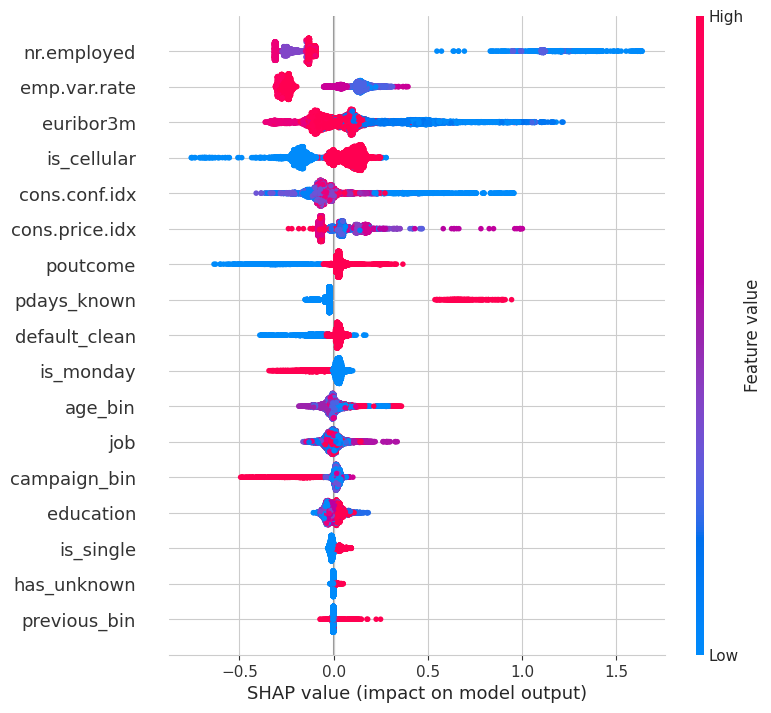

In [275]:
# якщо імпорт падає: !pip install shap
import shap

contrib = final_lgbm.predict(X_vb, pred_contrib=True)   # 17 ознак + база в останній колонці
sv_vals, sv_base = contrib[:, :-1], contrib[:, -1]
raw = final_lgbm.predict(X_vb, raw_score=True)
print('внески + база = передбачення:', np.allclose(sv_vals.sum(axis=1) + sv_base, raw))   # True

# для кольору на графіку категорії замінюю їхніми кодами
X_plot = X_vb.copy()
for c in pbm.CAT_COLS:
    X_plot[c] = X_plot[c].cat.codes

sv = shap.Explanation(values=sv_vals, base_values=sv_base,
                      data=X_plot.to_numpy(), feature_names=list(X_vb.columns))

mean_abs = pd.Series(np.abs(sv_vals).mean(axis=0), index=X_vb.columns).sort_values(ascending=False)
print(mean_abs.round(3))

shap.plots.beeswarm(sv, max_display=17)

Внески SHAP точно дорівнюють передбаченню моделі. Напрямки ознак клієнта збігаються з таблицями EDA.

Попередній контакт і успіх попередньої кампанії підвищують шанс депозиту. Стаціонарний телефон, невідомий кредитний статус, понеділок і шість та більше дзвінків його знижують. Низька зайнятість дає внесок від +0.5 до +1.6 log-odds і працює як перемикач режиму: період низької зайнятості проти решти.

Макроколонки разом дають 64 % середнього абсолютного внеску SHAP проти 83 % gain. emp.var.rate за SHAP друга, а за gain лише сьома. Отже, метод по-різному ділить заслугу між корельованими макроколонками, і впевнено можна говорити лише про блок, а не про порядок усередині нього.

**8.1. Залежність внеску від значення ознаки**

Для nr.employed і euribor3m будую графіки залежності внеску SHAP від значення. Колір показує другу ознаку: якщо точки одного значення розходяться за кольором, дві ознаки взаємодіють. Для nr.employed окремо рахую таблицю за кожним значенням: кількість рядків, конверсію і середній внесок.

                n   rate   shap
nr.employed                    
4963.6        116  0.517  1.143
4991.6        145  0.524  1.392
5008.7        126  0.579  1.274
5017.5        214  0.453  1.204
5023.5         35  0.486  1.222
5076.2        337  0.377  1.112
5099.1       1701  0.135 -0.237
5176.3          4  0.000 -0.262
5191.0       1588  0.035 -0.311
5195.8        742  0.050 -0.125
5228.1       3230  0.048 -0.123


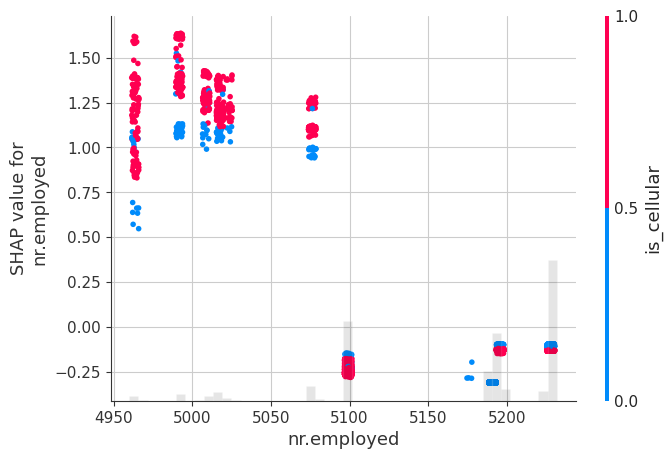

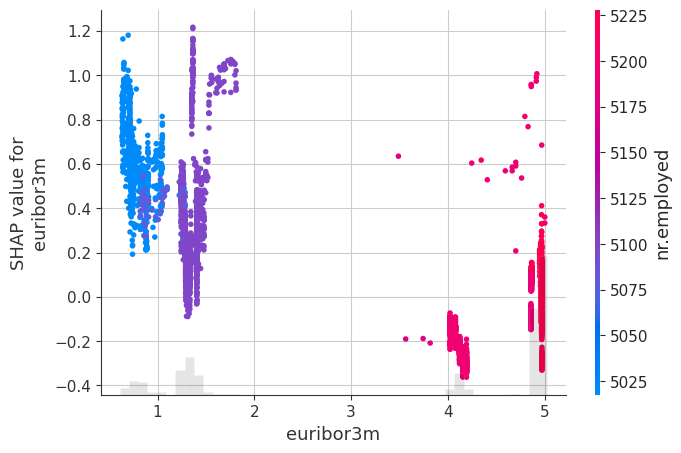

In [276]:
i_ne = list(X_vb.columns).index('nr.employed')

ne_table = (pd.DataFrame({'nr.employed': X_vb['nr.employed'].to_numpy(),
                          'shap': sv_vals[:, i_ne],
                          'y': y_vb.to_numpy()})
              .groupby('nr.employed')
              .agg(n=('y', 'size'), rate=('y', 'mean'), shap=('shap', 'mean')))
print(ne_table.round(3))

shap.plots.scatter(sv[:, 'nr.employed'], color=sv[:, 'is_cellular'])
shap.plots.scatter(sv[:, 'euribor3m'], color=sv[:, 'nr.employed'])

Внесок nr.employed працює як перемикач. При значеннях до 5076 внесок від +1.1 до +1.4 log-odds, а конверсія від 0.38 до 0.58. При значеннях від 5 099 внесок від −0.1 до −0.3, а конверсія не вище 0.14. Колонка має лише 11 значень, по одному на квартал, тому модель розпізнає квартали, а не силу економіки. У періоді низької зайнятості канал зв'язку посилює ефект: мобільні клієнти отримують більший внесок, ніж стаціонарні.

Для euribor3m при майже однаковій ставці внесок розкидається від −0.3 до +1.2. Модель розрізняє крихітні щоденні зміни ставки, тобто окремі дні кампанії. Це підтверджує висновок пункту 7: макроколонки модель використовує як дату.

**8.2. Пояснення окремих клієнтів**

Два клієнти, які справді підписали депозит: з найвищою ймовірністю за моделлю і з найнижчою. Графік waterfall показує, як внески ознак ведуть від середнього передбачення моделі до передбачення для цього клієнта. Категорії підписані текстом.

In [277]:
p_vb = final_lgbm.predict_proba(X_vb)[:, 1]
pos = np.where(y_vb.to_numpy() == 1)[0]          # позиції позитивних клієнтів у val
hit  = pos[np.argmax(p_vb[pos])]
miss = pos[np.argmin(p_vb[pos])]

to_p = lambda z: 1 / (1 + np.exp(-z))
rank = pd.Series(p_vb).rank(ascending=False)
print('база: ймовірність', round(to_p(sv_base[0]), 3))
for name, i in [('влучання', hit), ('промах', miss)]:
    print(f'{name:9s} ймовірність {p_vb[i]:.3f}  місце {int(rank[i])} з {len(p_vb)}')

# підписи категорій текстом, а не кодами
sv_disp = shap.Explanation(values=sv_vals, base_values=sv_base,
                           data=X_plot.to_numpy(),
                           display_data=X_vb.astype(str).to_numpy(),
                           feature_names=list(X_vb.columns))

база: ймовірність 0.075
влучання  ймовірність 0.876  місце 2 з 8238
промах    ймовірність 0.020  місце 8232 з 8238


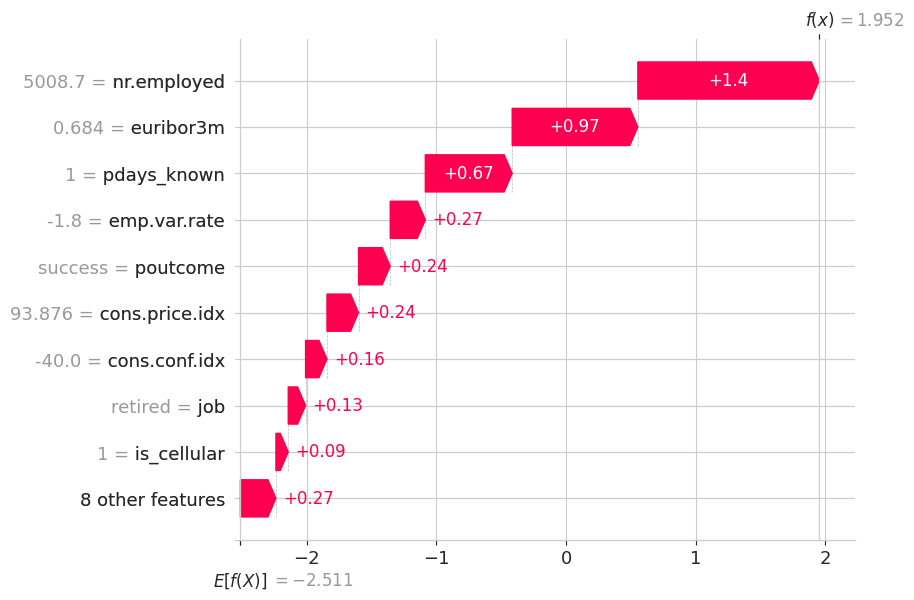

In [278]:
shap.plots.waterfall(sv_disp[hit], max_display=10)

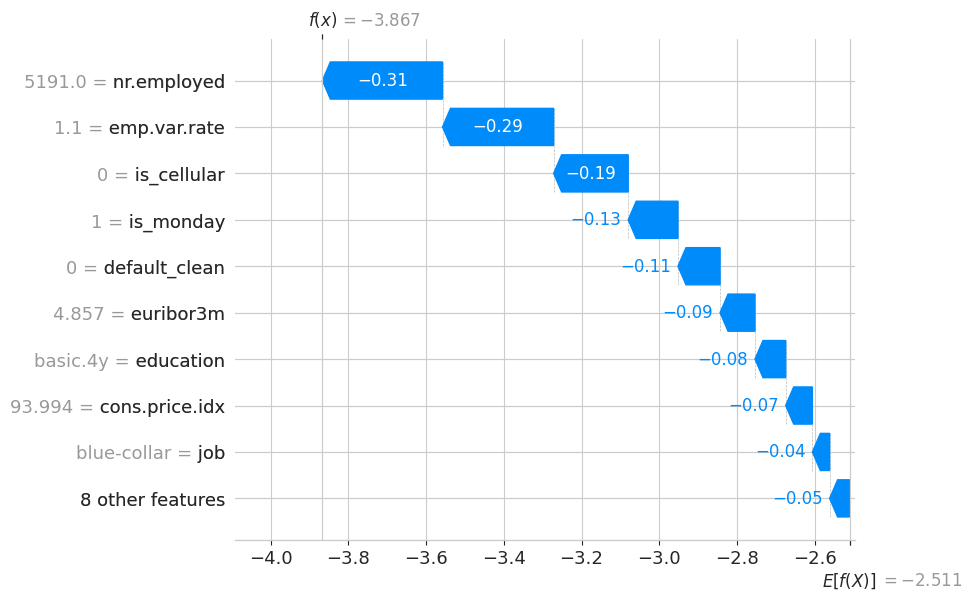

In [279]:
shap.plots.waterfall(sv_disp[miss], max_display=10)

Для найкращого влучання модель піднімається від середнього передбачення на 4.5 log-odds, до ймовірності 0.88. Дві третини цього підйому дають макроколонки, тобто 2010 рік. П'яту частину дають попередній контакт і успіх попередньої кампанії. Решту дають професія retired і мобільний зв'язок. Профіль відповідає здоровому глузду, але й тут головну впевненість дає період, а не клієнт.

Для найбільшого промаху всі внески малі й від'ємні. Це травень 2008 року з конверсією 3 %, стаціонарний телефон, понеділок і невідомий кредитний статус. Модель оцінила шанс у 2 %, і для такого профілю це правильна оцінка: клієнт виявився рідкісним винятком. Тому не кожен промах вказує на ваду моделі.

**9. Аналіз помилок**

Задача ранжування з обмеженою ємністю, тому більшість пропущених позитивних клієнтів пропущені через брак дзвінків, а не через помилку моделі. Тому спершу перевіряю, чи правильно модель оцінює шанс. Ділю val на 10 груп за ймовірністю і порівнюю середню ймовірність з реальною конверсією. Відхилення понад 2 стандартні помилки вважаю систематичним.

In [280]:
cal = pd.DataFrame({'p': p_vb, 'y': y_vb.to_numpy()})
cal['дециль'] = pd.qcut(cal['p'].rank(method='first'), 10, labels=range(1, 11))

cal_t = cal.groupby('дециль', observed=True).agg(n=('y', 'size'), p_mean=('p', 'mean'),
                                                 rate=('y', 'mean'), yes=('y', 'sum'))
cal_t['різниця'] = cal_t['rate'] - cal_t['p_mean']
cal_t['SE'] = np.sqrt(cal_t['p_mean'] * (1 - cal_t['p_mean']) / cal_t['n'])
cal_t['z'] = cal_t['різниця'] / cal_t['SE']
print(cal_t.round(3))
print()
print('середня ймовірність', round(cal['p'].mean(), 4), '| частка позитивів', round(cal['y'].mean(), 4))

          n  p_mean   rate  yes  різниця     SE      z
дециль                                                
1       824   0.026  0.030   25    0.004  0.006  0.758
2       824   0.033  0.030   25   -0.003  0.006 -0.449
3       824   0.041  0.040   33   -0.001  0.007 -0.076
4       823   0.047  0.033   27   -0.014  0.007 -1.952
5       824   0.053  0.040   33   -0.013  0.008 -1.622
6       824   0.061  0.053   44   -0.008  0.008 -0.904
7       823   0.069  0.066   54   -0.004  0.009 -0.434
8       824   0.087  0.081   67   -0.005  0.010 -0.540
9       824   0.196  0.210  173    0.014  0.014  0.983
10      824   0.504  0.542  447    0.038  0.017  2.195

середня ймовірність 0.1117 | частка позитивів 0.1126


Модель добре відкалібрована: середня ймовірність 0.112 при частці позитивів 0.113. У дев'яти децилях з десяти різниця між передбаченою і реальною конверсією менша за дві стандартні помилки. Лише в найвищому децилі модель трохи занижує шанс, 0.50 проти 0.54, і при десяти перевірках це слабкий сигнал.

Децилі 9 і 10 містять дві третини позитивних клієнтів. Решта третина, 308 клієнтів, розсипана серед 6 590 клієнтів з шансом від 3 до 8%. Модель оцінює їхній шанс правильно, але не має ознак, щоб відрізнити їх від сусідів. Ці помилки неминучі з наявними даними: інша модель їх не виправить, допомогти можуть лише нові дані про клієнта.

**9.1. Систематичні помилки за сегментами**

Для кожного рівня ознак порівнюю середню ймовірність моделі з реальною конверсією на val. Перевіряю близько 50 сегментів, тому відхилення від 2 до 3 стандартних помилок вважаю лише кандидатом, а понад 3 справжнім сигналом.

In [281]:
seg_src = X_vb.copy()
seg_src['year']   = df.loc[X_vb.index, 'year'].to_numpy()
seg_src['режим']  = np.where(X_vb['nr.employed'] <= 5076.2, 'низька зайнятість', 'висока зайнятість')

SEG_COLS = ['year', 'режим', 'is_cellular', 'poutcome', 'pdays_known', 'age_bin', 'job',
            'education', 'campaign_bin', 'is_monday', 'default_clean', 'is_single', 'has_unknown']

parts = []
for col in SEG_COLS:
    t = (pd.DataFrame({'рівень': seg_src[col].astype(str).to_numpy(), 'p': p_vb, 'y': y_vb.to_numpy()})
           .groupby('рівень').agg(n=('y', 'size'), p_mean=('p', 'mean'), rate=('y', 'mean')))
    t.insert(0, 'ознака', col)
    parts.append(t.reset_index())

seg = pd.concat(parts, ignore_index=True)
seg['різниця'] = seg['rate'] - seg['p_mean']
seg['SE'] = np.sqrt(seg['p_mean'] * (1 - seg['p_mean']) / seg['n'])
seg['z'] = seg['різниця'] / seg['SE']

print('сегментів:', len(seg))
print(seg[seg['z'].abs() > 2].sort_values('z', key=abs, ascending=False).round(3).to_string(index=False))

сегментів: 50
Empty DataFrame
Columns: [рівень, ознака, n, p_mean, rate, різниця, SE, z]
Index: []


In [282]:
print(seg.sort_values('z', key=abs, ascending=False).head(5).round(3).to_string(index=False))

 рівень      ознака    n  p_mean  rate  різниця    SE      z
   2008        year 5564   0.050 0.045   -0.005 0.003 -1.704
      1 has_unknown 2055   0.076 0.067   -0.009 0.006 -1.583
student         job  164   0.300 0.354    0.054 0.036  1.506
   2009        year 2287   0.194 0.206    0.012 0.008  1.460
success    poutcome  268   0.620 0.660    0.041 0.030  1.372


Жоден з 50 сегментів не має відхилення, більшого за дві стандартні помилки, хоча при такій кількості перевірок два або три випадкові відхилення були б нормою. На випадковому розбитті модель правильно оцінює шанс у кожній групі клієнтів: за роком, каналом, віком, професією, освітою та історією контактів. Val береться з тих самих місяців, що й train, тому цей результат стосується лише знайомих періодів. Перевірку на майбутньому періоді роблю окремо, на 2010 році.

**9.2. Калібрування на 2010 році і робоча точка**

Модель, навчена на 2008 і 2009 роках, оцінює клієнтів 2010 року. Порівнюю середню ймовірність з реальною конверсією за децилями. Потім на val беру топ-2.43 %, що відповідає 1 000 дзвінкам, і порівнюю клієнтів, які погодились, з клієнтами, які відмовились.

In [283]:
d_bt = pbm.preprocess_data(fresh, kind='boost', split='time')
m_t  = lgbm_factory(**rs_lgbm_v1.best_params_).fit(d_bt['X_train'], d_bt['train_targets'])
p_t  = m_t.predict_proba(d_bt['X_val'])[:, 1]
y_t  = d_bt['val_targets'].to_numpy()

print('2010: середня ймовірність', round(p_t.mean(), 3), '| реальна частка', round(y_t.mean(), 3))

cal_t10 = pd.DataFrame({'p': p_t, 'y': y_t})
cal_t10['дециль'] = pd.qcut(cal_t10['p'].rank(method='first'), 10, labels=range(1, 11))
print(cal_t10.groupby('дециль', observed=True)
             .agg(n=('y', 'size'), p_mean=('p', 'mean'), rate=('y', 'mean')).round(3))

2010: середня ймовірність 0.313 | реальна частка 0.521
          n  p_mean   rate
дециль                    
1       206   0.118  0.184
2       206   0.161  0.340
3       206   0.191  0.432
4       205   0.224  0.439
5       206   0.261  0.461
6       206   0.307  0.481
7       205   0.361  0.644
8       206   0.412  0.728
9       206   0.492  0.689
10      206   0.600  0.816


In [284]:
k = int(round(len(p_vb) * pbm.BUSINESS_SHARE))          # 200
top = np.argsort(-p_vb)[:k]
top_df = seg_src.iloc[top].copy()
top_df['y'] = y_vb.to_numpy()[top]
print(f'топ-{k}: погодились {top_df["y"].sum()}, відмовились {(top_df["y"] == 0).sum()}')
print()

flags = pd.DataFrame({
    'низька зайнятість': top_df['режим'] == 'низька зайнятість',
    'poutcome success':  top_df['poutcome'].astype(str) == 'success',
    'pdays_known':       top_df['pdays_known'] == 1,
    'мобільний':         top_df['is_cellular'] == 1,
    'retired або student': top_df['job'].astype(str).isin(['retired', 'student']),
    'campaign 1':        top_df['campaign_bin'].astype(str) == '1',
})
print(flags.groupby(top_df['y'].map({1: 'погодились', 0: 'відмовились'})).mean().T.round(2))

топ-200: погодились 149, відмовились 51

y                    відмовились  погодились
низька зайнятість           0.98        0.99
poutcome success            0.80        0.91
pdays_known                 0.84        0.93
мобільний                   0.96        0.93
retired або student         0.35        0.31
campaign 1                  0.37        0.56


На 2010 році модель, навчена на 2008 і 2009 роках, сильно занижує шанс: середня ймовірність 0.31 при реальній частці 0.52. Заниження є в кожному децилі, але порядок клієнтів майже зберігається: реальна конверсія зростає від 0.18 у нижньому децилі до 0.82 у верхньому. Тобто в новому періоді модель правильно ранжує, але не знає, наскільки зріс загальний рівень. Для вибору найкращих клієнтів це не шкодить. Для порогу за ймовірністю або прогнозу кількості депозитів шкодить.

У топ-2.43% val погодились 149 клієнтів з 200. Ті, хто відмовився, майже не відрізняються від тих, хто погодився: обидві групи складаються з клієнтів з успішною попередньою кампанією в добрий період. Помітно відрізняє їх лише кількість контактів: перший дзвінок у кампанії отримали 56% тих, хто погодився, і 37% тих, хто відмовився. Група відмов мала лише 51 клієнта, тому це кандидат для перевірки.

Як покращити рішення:

1) Регулярно перенавчати модель або хоча б перекалібрувати ймовірності на найсвіжіших місяцях, бо рівень конверсії змінюється з часом.
2) Замінити сирі макроколонки ознакою режиму, щоб модель не ділила дані за датою. Перевіряти це варто часовим розбиттям, а не випадковим.
3) Додати дані про клієнта, яких немає в наборі: фінансовий стан, продукти банку, історію звернень. Третина позитивних клієнтів має шанс від 3 до 8%, і з наявними ознаками модель не може їх відокремити.
4) Детальніше врахувати кількість контактів у поточній кампанії, ніж чотири групи campaign_bin.